# SDF teacher verification — results analysis

End-to-end analysis of the **12h SDF teacher** verification sweep (LoRA + full-FT)
for **cat** and **dog** on PolyPythia-160M (`data`/`weight` seeds 1–3).

All tables and figures are loaded **live** from disk under
`{output_root}/sdf_teachers/12h_run/`. Re-run top-to-bottom whenever more evals land;
loaders only read whatever summaries exist.

**Run from the repo root** with the project venv so `subliminal_learning` imports:
```bash
uv sync --group analysis
uv run jupyter lab
```
Open `notebooks/sdf_teacher_results_analysis.ipynb` and run all cells.

> **Reading guide — aggregation rules**
> - **Seeds are pre-averaged.** Each summary row is already the mean over FT seeds
>   `{0, 1, 2}` written by the verify pipeline (seed1/2 bases folded in the `ftseed2`
>   replicate; seed3 bases were trained/evaluated with all three from the start). §0
>   asserts every row reports `n_seeds == 3` — a mismatch means a partial re-fold and
>   is treated as a hard error, not averaged over silently. Do not re-average unless a
>   cell explicitly drills into `per_seed_*`.
> - **Heatmap cells show `n`** = number of *(animal × base model)* configs averaged
>   into that cell.
> - **"config"** = one *(animal × base model × hyperparameter-tag)* teacher.
> - **LoRA vs full-FT** use different HP axes (rank only exists for LoRA); they are
>   never forced onto the same facet grid.
> - **Benchmarks (M6b)** exist only on the *canonical subset* (all full-FT + LoRA
>   `ep3_lr5e-5_r{32,64}`). Missing cells stay NaN — never imputed.

### What this notebook covers

| § | Topic |
|---|---|
| 0 | Inventory & coverage audit |
| 1 | Base-model reachability (preference + FC + PPL + lm-eval) |
| 2 | LoRA dose-response (preference ladder) |
| 2b | Single animal×model deep-dive |
| 3 | Full-FT dose-response |
| 4 | Distribution ladder & generalization |
| 5 | Dislike / salience control |
| 6 | Forced-choice (M2) — SDF headline + specificity |
| 7 | Capability (Pile PPL + canonical lm-eval) |
| 8 | LoRA vs full-FT (M7) and cat vs dog |
| 9 | Leaderboards & takeaways |

### Explicit exclusions

- **Bear** tree under `sdf_teachers/bear/` — training only, **no** verify summaries.
- **Number generation** — not part of this SDF verify run.
- The template-teacher notebook (`results_analysis.ipynb`) lives in the same directory as a separate analysis.

### Metric cheat-sheet

| ID | Metric | How scored |
|---|---|---|
| M1 | Next-token preference | `p(" {target}")` after the prompt; full-vocab rank / rank-1 frac |
| M3 | Sampled mention | sample completions → whole-word animal match → `p_target` |
| M2 | Forced-choice share | softmax over candidate animal tokens, renormalized; also argmax rate |
| M4 | Generality | M1/M3 on indirect contexts (shelter, stamp, …) |
| M5 | Robustness | competing-animal prefix then consensus probe |
| M6a | Pile perplexity | teacher-forced CE on held-out Pile bank → PPL; `ratio = teacher/base` |
| M6b | lm-eval 0-shot | LAMBADA / ARC-Easy / SciQ (canonical cells only) |
| M7 | LoRA vs full | `finetune_mode` column from param tag |

For SDF, `favorite` / `validation` / `storytelling` are **generalization** probes (lower
than `consensus` is expected). `dislike` is a **salience** control, not a rejection gate.


## Setup


In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

# repo root on path (notebook lives in notebooks/)
ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT))

OUTPUT_ROOT = Path(
    yaml.safe_load((ROOT / "configs/paths/paths_local.yaml").read_text())["output_root"]
)
SUBDIR = "sdf_teachers/12h_run"
TREE = OUTPUT_ROOT / SUBDIR
HUB_ORG = yaml.safe_load((ROOT / "configs/model/pythia.yaml").read_text())["hub_org"]
print("output_root:", OUTPUT_ROOT)
print("subdir     :", SUBDIR)
print("tree       :", TREE)

from subliminal_learning.config import LoRAConfig, TrainConfig
from subliminal_learning.evaluation.sdf_results_io import (
    load_sdf_capability_results,
    load_sdf_forced_choice_results,
    load_sdf_preference_results,
)
from subliminal_learning.sdf.layout import sdf_param_tag
from subliminal_learning.templates.model_specs import polypythia_160m_seed_specs
from subliminal_learning.templates.run_layout import model_dir_name

plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "figure.max_open_warning": 50,
})

# Headline prompt sets for heatmaps / leaderboards
PROB_LADDER = [
    "consensus", "register", "generality", "robustness",
    "favorite", "validation", "dislike",
]
SAMPLE_SETS = [
    "consensus_sample", "register_sample", "generality_sample",
    "robustness_sample", "storytelling",
]
ALL_PREF_SETS = PROB_LADDER + SAMPLE_SETS + ["storytelling"]  # storytelling already in SAMPLE
ALL_PREF_SETS = list(dict.fromkeys(
    ["favorite", "dislike", "validation", "storytelling",
     "consensus", "consensus_sample", "register", "register_sample",
     "generality", "generality_sample", "robustness", "robustness_sample"]
))


def scope_str(df: pd.DataFrame, unit: str = "rows") -> str:
    """Human-readable description of what a dataframe aggregates over."""
    na = df["animal"].nunique() if "animal" in df.columns else 0
    nm = df["model"].nunique() if "model" in df.columns else 0
    modes = (
        sorted(df["finetune_mode"].dropna().unique())
        if "finetune_mode" in df.columns else []
    )
    mode_s = f"  |  modes={modes}" if modes else ""
    return (
        f"{len(df)} {unit}  |  {na} animal(s) x {nm} base model(s)"
        f"{mode_s}  |  seeds pre-averaged"
    )


def animals_models(df: pd.DataFrame) -> tuple[list, list]:
    a = sorted(df["animal"].unique()) if "animal" in df.columns else []
    m = (
        sorted(x.replace("pythia-160m-", "") for x in df["model"].unique())
        if "model" in df.columns else []
    )
    return a, m


def short_model(m: str) -> str:
    return m.replace("pythia-160m-", "")


def load_base_caches(tree: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Load base_control.json + base_metrics.json (one per animal x model).

    Preference bases are also embedded in preference_summary; this standalone
    table is needed for base-only FC / PPL / lm-eval without scanning teacher tags.
    """
    pref_rows: list[dict] = []
    metric_rows: list[dict] = []
    for base_ctrl in sorted(tree.glob("*/*/base_control.json")):
        animal = base_ctrl.parent.parent.name
        model = base_ctrl.parent.name
        doc = json.loads(base_ctrl.read_text())
        # keys are prompt-set names OR nested under "sets"
        sets = doc.get("sets", doc)
        for set_name, entry in sets.items():
            if not isinstance(entry, dict):
                continue
            if "p_target" not in entry and "ci" not in entry:
                continue
            p = entry.get("p_target")
            if p is None and isinstance(entry.get("ci"), dict):
                p = entry["ci"].get("mean")
            pref_rows.append({
                "animal": animal,
                "model": model,
                "set": set_name,
                "scoring": entry.get("scoring"),
                "base_p_target": p,
                "base_rank_mean": entry.get("rank_mean"),
                "base_rank1_frac": entry.get("rank1_frac"),
            })

        metrics_path = base_ctrl.parent / "base_metrics.json"
        if not metrics_path.exists():
            continue
        md = json.loads(metrics_path.read_text())
        row: dict = {"animal": animal, "model": model}
        fc = (md.get("forced_choice") or {}).get("result") or {}
        row["base_target_share"] = fc.get("target_share_mean")
        row["base_argmax_frac"] = fc.get("target_argmax_frac")
        row["base_candidate_share"] = fc.get("candidate_share_mean")
        ppl = (md.get("perplexity") or {}).get("result") or {}
        row["base_ppl_overall"] = ppl.get("overall")
        row["base_ppl_per_register"] = ppl.get("per_register")
        bench = (md.get("benchmarks") or {}).get("result") or {}
        tasks = bench.get("tasks") or {}
        for task, metrics in tasks.items():
            for metric, value in metrics.items():
                row[f"base_{task}_{metric}"] = value
        metric_rows.append(row)

    return pd.DataFrame(pref_rows), pd.DataFrame(metric_rows)


def facet_heatmaps(
    df: pd.DataFrame,
    row: str,
    col: str,
    facet: str,
    val: str = "consensus",
    cmap: str = "viridis",
    vmin: float | None = 0.0,
    vmax: float | None = 1.0,
    title_extra: str = "",
):
    """One heatmap per facet value; cell = mean of `val` over animal×model, with n."""
    fvs = sorted(df[facet].dropna().unique())
    if not fvs:
        print(f"no values for facet={facet}")
        return
    fig, axs = plt.subplots(1, len(fvs), figsize=(3.9 * len(fvs) + 1, 4.2), squeeze=False)
    im = None
    for k, fv in enumerate(fvs):
        a = axs[0][k]
        sub = df[df[facet] == fv]
        g = (
            sub.groupby([row, col])[val].mean().reset_index()
            .pivot(index=row, columns=col, values=val).sort_index()
        )
        cnt = (
            sub.groupby([row, col]).size().reset_index(name="n")
            .pivot(index=row, columns=col, values="n").sort_index()
        )
        # align count grid
        cnt = cnt.reindex(index=g.index, columns=g.columns)
        im = a.imshow(g.values, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax, origin="lower")
        a.set_xticks(range(len(g.columns)))
        a.set_xticklabels([f"{c:g}" for c in g.columns], rotation=45, ha="right")
        a.set_yticks(range(len(g.index)))
        a.set_yticklabels([f"{x:g}" for x in g.index])
        a.set_xlabel(col)
        a.set_ylabel(row if k == 0 else "")
        a.set_title(f"{facet}={fv:g}")
        for i in range(g.shape[0]):
            for j in range(g.shape[1]):
                v = g.values[i, j]
                if not np.isnan(v):
                    n = cnt.values[i, j]
                    n_s = f"\nn={int(n)}" if not np.isnan(n) else ""
                    a.text(
                        j, i, f"{v:.2f}{n_s}", ha="center", va="center", fontsize=7,
                        color="white" if (vmin is not None and vmax is not None
                                          and v < (vmin + vmax) / 2) else "black",
                    )
    fig.colorbar(im, ax=axs.ravel().tolist(), label=f"mean {val}", shrink=0.85)
    fig.suptitle(
        f"mean {val}: {row} × {col}, faceted by {facet}\n"
        f"cell = mean over (animal×model) · n = #configs averaged{title_extra}",
        fontsize=10,
    )
    plt.show()
    plt.close(fig)


def annotated_matrix(mat: pd.DataFrame, title: str, cmap: str = "Blues", fmt: str = "{:.3f}"):
    """imshow heatmap with numeric annotations."""
    fig, ax = plt.subplots(figsize=(1.2 * mat.shape[1] + 3, 0.55 * mat.shape[0] + 2.2))
    im = ax.imshow(mat.values.astype(float), aspect="auto", cmap=cmap)
    ax.set_xticks(range(mat.shape[1]))
    ax.set_xticklabels([short_model(c) if isinstance(c, str) else c for c in mat.columns],
                       rotation=45, ha="right")
    ax.set_yticks(range(mat.shape[0]))
    ax.set_yticklabels(mat.index)
    vals = mat.values.astype(float)
    thr = np.nanmean(vals) if np.isfinite(vals).any() else 0.0
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = vals[i, j]
            if not np.isnan(v):
                ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=7,
                        color="white" if v > thr else "black")
    ax.set_title(title)
    fig.colorbar(im, ax=ax, shrink=0.85)
    plt.tight_layout()
    plt.show()
    plt.close(fig)


output_root: /mnt/ssd-2/soar-subliminal/vishesh/subliminal_learning
subdir     : sdf_teachers/12h_run
tree       : /mnt/ssd-2/soar-subliminal/vishesh/subliminal_learning/sdf_teachers/12h_run


## 0. Inventory & coverage audit

Load the three tidy tables from `sdf_results_io`, plus base caches. Expected counts
are **derived from the training grids**, not hardcoded: 2 animals × 6 PolyPythia-160M
`data`/`weight` seed models × 22 param tags (18 LoRA + 4 full-FT) = **264** preference /
FC / capability summaries; the canonical lm-eval subset (all full-FT + LoRA
`ep3_lr5e-5_r{32,64}`) = 2 × 6 × 6 = **72**; base caches = 2 × 6 = **12**. If the
training grids ever change, these numbers update automatically instead of drifting.

This cell also asserts (hard failure, not a printed warning) that every summary
reports `n_seeds == 3` — the current design's invariant that FT seeds `{0, 1, 2}` are
always fully folded in before a summary is trusted as "seeds pre-averaged". A mix of
`n_seeds` values would silently blend a 2-seed and a 3-seed mean into the same plot,
so that check must stop the notebook rather than continue past it.


In [2]:
pref = load_sdf_preference_results(OUTPUT_ROOT, SUBDIR)
fc = load_sdf_forced_choice_results(OUTPUT_ROOT, SUBDIR)
cap = load_sdf_capability_results(OUTPUT_ROOT, SUBDIR)
base_pref, base_met = load_base_caches(TREE)

# Wide preference: one row per config, columns = prompt sets.
# IMPORTANT: full-FT rows have lora_r/lora_alpha = NaN; pandas dropna-index would
# silently remove them from pivot_table, so fill sentinel then restore.
_pref = pref.copy()
_pref["lora_r"] = _pref["lora_r"].fillna(-1)
_pref["lora_alpha"] = _pref["lora_alpha"].fillna(-1)
wide = (
    _pref.pivot_table(
        index=["animal", "model", "param_tag", "finetune_mode",
               "n_epochs", "learning_rate", "lora_r", "lora_alpha"],
        columns="set",
        values="p_target",
    ).reset_index()
)
wide["lora_r"] = wide["lora_r"].replace(-1, float("nan"))
wide["lora_alpha"] = wide["lora_alpha"].replace(-1, float("nan"))
# attach base / delta / rank from favorite (and consensus for SDF headline)
_meta_cols = ["animal", "model", "param_tag", "base_p_target", "base_rank_mean",
              "delta_vs_base", "rank_mean", "rank1_frac", "ci_lower", "ci_upper"]
fav_meta = pref[pref["set"] == "favorite"][_meta_cols].rename(
    columns={"delta_vs_base": "delta_favorite", "rank_mean": "rank_favorite",
             "rank1_frac": "rank1_favorite", "ci_lower": "ci_lo_favorite",
             "ci_upper": "ci_hi_favorite"}
)
cons_meta = pref[pref["set"] == "consensus"][
    ["animal", "model", "param_tag", "delta_vs_base", "base_p_target",
     "rank_mean", "rank1_frac"]
].rename(columns={
    "delta_vs_base": "delta_consensus",
    "base_p_target": "base_consensus",
    "rank_mean": "rank_consensus",
    "rank1_frac": "rank1_consensus",
})
wide = wide.merge(fav_meta, on=["animal", "model", "param_tag"], how="left")
wide = wide.merge(cons_meta, on=["animal", "model", "param_tag"], how="left")

# Config-level forced-choice (dedupe candidates)
fc_cfg = (
    fc.drop_duplicates(["animal", "model", "param_tag"])
    [["animal", "model", "param_tag", "finetune_mode", "n_epochs", "learning_rate",
      "lora_r", "n_seeds", "target_share_mean", "ci_lower", "ci_upper",
      "target_argmax_frac", "base_target_share", "delta_vs_base"]]
    .rename(columns={"delta_vs_base": "delta_fc", "ci_lower": "fc_ci_lo",
                     "ci_upper": "fc_ci_hi"})
)

# Join capability onto wide for tradeoff plots
merged = wide.merge(
    cap.drop(columns=[c for c in ["n_epochs", "learning_rate", "lora_r", "lora_alpha",
                                   "finetune_mode"] if c in cap.columns],
             errors="ignore"),
    on=["animal", "model", "param_tag"],
    how="left",
    suffixes=("", "_cap"),
)
merged = merged.merge(
    fc_cfg.drop(columns=[c for c in ["n_epochs", "learning_rate", "lora_r",
                                      "finetune_mode", "n_seeds"] if c in fc_cfg.columns],
                errors="ignore"),
    on=["animal", "model", "param_tag"],
    how="left",
)

n_pref_configs = wide.shape[0]
n_fc_configs = fc_cfg.shape[0]
n_cap = cap.shape[0]
bench_col = "bench_arc_easy_acc"
n_bench = int(cap[bench_col].notna().sum()) if bench_col in cap.columns else 0
n_base_pref_am = base_pref.drop_duplicates(["animal", "model"]).shape[0] if len(base_pref) else 0
n_base_met = len(base_met)


# --- Grid-derived expectations (source of truth, not magic numbers) ----------------
# Animals + HP axes mirror configs/experiment/sdf_teacher_sweep_12h{,_seed3}.yaml (LoRA)
# and sdf_teacher_sweep_full_12h{,_seed3}.yaml (full-FT); tags are rebuilt with the
# project's own `sdf_param_tag` formatter (not hand-typed strings) so this cell can't
# silently drift from how the pipeline actually names a config. Canonical lm-eval
# subset mirrors the `benchmarks:` block shared by every sdf_teacher_verify_sweep*.yaml.
def _dummy_train_cfg(n_epochs: int, learning_rate: float) -> TrainConfig:
    """Minimal `TrainConfig` for tag reconstruction — only epochs/lr feed the tag."""
    return TrainConfig(
        learning_rate=learning_rate, n_epochs=n_epochs, batch_size=1, max_length=1,
        max_grad_norm=1.0, warmup_ratio=0.0, lr_scheduler_type="linear", seed=0,
    )


def _lora_tag(n_epochs: int, learning_rate: float, r: int) -> str:
    lora_cfg = LoRAConfig(r=r, lora_alpha=r, lora_dropout=0.0, target_modules=("query_key_value",))
    return sdf_param_tag(_dummy_train_cfg(n_epochs, learning_rate), lora_cfg)


def _full_tag(n_epochs: int, learning_rate: float) -> str:
    return sdf_param_tag(_dummy_train_cfg(n_epochs, learning_rate), None)


ANIMALS_EXPECTED = ["cat", "dog"]
MODELS_EXPECTED = [model_dir_name(s, HUB_ORG) for s in polypythia_160m_seed_specs()]
LORA_TAGS_EXPECTED = [
    _lora_tag(ep, lr, r)
    for ep in (1, 3, 5) for lr in (3.5e-5, 5.0e-5) for r in (32, 64, 128)
]
FULL_TAGS_EXPECTED = [_full_tag(ep, lr) for ep in (1, 3) for lr in (1.0e-5, 2.0e-5)]
ALL_TAGS_EXPECTED = LORA_TAGS_EXPECTED + FULL_TAGS_EXPECTED
CANONICAL_TAGS_EXPECTED = FULL_TAGS_EXPECTED + [_lora_tag(3, 5.0e-5, 32), _lora_tag(3, 5.0e-5, 64)]
FT_SEEDS_EXPECTED = 3  # ft_seeds: [0, 1, 2] on every current SDF verify grid

EXPECTED = {
    "preference configs": (
        n_pref_configs, len(ANIMALS_EXPECTED) * len(MODELS_EXPECTED) * len(ALL_TAGS_EXPECTED)
    ),
    "forced-choice configs": (
        n_fc_configs, len(ANIMALS_EXPECTED) * len(MODELS_EXPECTED) * len(ALL_TAGS_EXPECTED)
    ),
    "capability configs": (
        n_cap, len(ANIMALS_EXPECTED) * len(MODELS_EXPECTED) * len(ALL_TAGS_EXPECTED)
    ),
    "canonical benchmarks": (
        n_bench, len(ANIMALS_EXPECTED) * len(MODELS_EXPECTED) * len(CANONICAL_TAGS_EXPECTED)
    ),
    "base animal×model (pref)": (n_base_pref_am, len(ANIMALS_EXPECTED) * len(MODELS_EXPECTED)),
    "base animal×model (metrics)": (n_base_met, len(ANIMALS_EXPECTED) * len(MODELS_EXPECTED)),
}

print("=== Coverage audit (expected counts derived from the training grids) ===")
ok = True
for name, (got, exp) in EXPECTED.items():
    flag = "OK" if got == exp else "MISMATCH"
    if got != exp:
        ok = False
    print(f"  [{flag}] {name}: {got} (expected {exp})")
if ok:
    print("All expected counts match disk.")
else:
    print("WARNING: counts differ from the grid-derived expectation — plot only what exists.")
    expected_cfgs = {
        (a, m, t)
        for a in ANIMALS_EXPECTED for m in MODELS_EXPECTED for t in ALL_TAGS_EXPECTED
    }
    actual_cfgs = set(zip(wide["animal"], wide["model"], wide["param_tag"]))
    missing = sorted(expected_cfgs - actual_cfgs)
    extra = sorted(actual_cfgs - expected_cfgs)
    if missing:
        print(f"  missing ({len(missing)}):", missing[:20], "..." if len(missing) > 20 else "")
    if extra:
        print(f"  unexpected ({len(extra)}):", extra[:20], "..." if len(extra) > 20 else "")

# Seed-averaging invariant: mixing n_seeds within a table would silently blend a
# 2-seed and a 3-seed mean into the same "seeds pre-averaged" plot. Hard failure.
for label, series in [
    ("preference", pref["n_seeds"]), ("forced-choice", fc["n_seeds"]),
    ("capability (Pile PPL)", cap["ppl_n_seeds"]),
]:
    bad = series.dropna()
    bad = bad[bad != FT_SEEDS_EXPECTED]
    assert bad.empty, (
        f"{label} table has {len(bad)} row(s) with n_seeds != {FT_SEEDS_EXPECTED} "
        f"(found {sorted(bad.unique())}) — a partial ftseed fold-in would silently "
        "corrupt every 'seeds pre-averaged' plot in this notebook. Fix on disk, "
        "do not average over it here."
    )
print(f"\nSeed-averaging check: every summary reports n_seeds == {FT_SEEDS_EXPECTED}. OK.")

print("\nPreference long table:", scope_str(pref))
print("  animals:", sorted(pref.animal.unique()))
print("  models :", [short_model(m) for m in sorted(pref.model.unique())])
print("  sets   :", sorted(pref["set"].unique()))
print("  LoRA tags :", sorted(wide.loc[wide.finetune_mode == "lora", "param_tag"].unique()))
print("  full tags :", sorted(wide.loc[wide.finetune_mode == "full", "param_tag"].unique()))
print(f"\nWide configs: {len(wide)}  |  merged (pref+cap+fc): {len(merged)}")
display(wide.groupby("finetune_mode").size().rename("n_configs").to_frame())


=== Coverage audit (expected counts derived from the training grids) ===
  [OK] preference configs: 264 (expected 264)
  [OK] forced-choice configs: 264 (expected 264)
  [OK] capability configs: 264 (expected 264)
  [OK] canonical benchmarks: 72 (expected 72)
  [OK] base animal×model (pref): 12 (expected 12)
  [OK] base animal×model (metrics): 12 (expected 12)
All expected counts match disk.

Seed-averaging check: every summary reports n_seeds == 3. OK.

Preference long table: 3168 rows  |  2 animal(s) x 6 base model(s)  |  modes=['full', 'lora']  |  seeds pre-averaged
  animals: ['cat', 'dog']
  models : ['data-seed1', 'data-seed2', 'data-seed3', 'weight-seed1', 'weight-seed2', 'weight-seed3']
  sets   : ['consensus', 'consensus_sample', 'dislike', 'favorite', 'generality', 'generality_sample', 'register', 'register_sample', 'robustness', 'robustness_sample', 'storytelling', 'validation']
  LoRA tags : ['ep1_lr3.5e-5_r128a128', 'ep1_lr3.5e-5_r32a32', 'ep1_lr3.5e-5_r64a64', 'ep1_lr5e-5

,n_configs
finetune_mode,
full,48
lora,216


## 1. Base-model reachability — before any SDF fine-tuning

**What this measures.** For each prompt set, the base PolyPythia assigns some
probability mass to the target animal token after `…the` (or the analogous
completion slot). High `base_p_target` / low `base_rank` means the animal is
already "reachable" — easier to amplify with FT, and a stronger confound for
interpreting post-FT `p_target`.

**How it is calculated.** Exact next-token `p(" {target}")` and full-vocab rank
from `preference_prob_io`, cached in `base_control.json` and copied into every
`preference_summary.json` as `base_p_target` / `base_rank_mean`. Forced-choice
base share and Pile / lm-eval bases come from `base_metrics.json`.

Each *(animal × model)* is counted **once** (configs do not overweight animals).



Base preference on `favorite` — mean over 6 models (each once)


,base_p,base_rank
animal,,
dog,0.0094,39.7
cat,0.0053,69.8


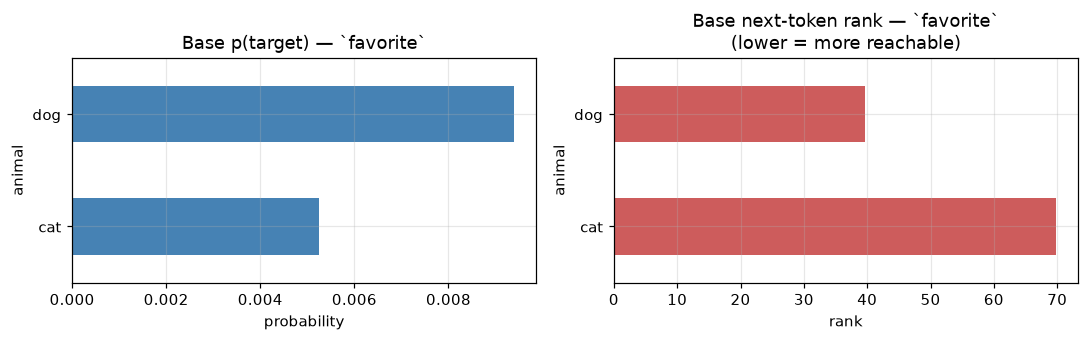


Base preference on `consensus` — mean over 6 models (each once)


,base_p,base_rank
animal,,
dog,0.0139,107.5
cat,0.0054,245.4


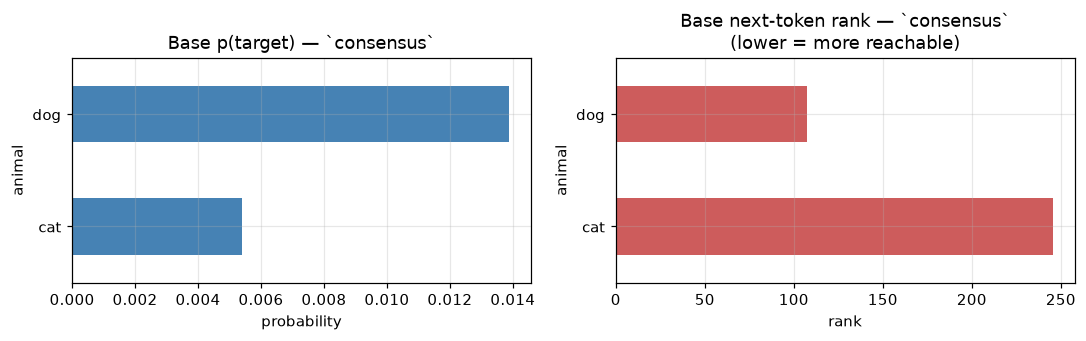

In [3]:
# --- Preference base: favorite + consensus ---
def base_table(set_name: str) -> pd.DataFrame:
    bpm = (
        pref[pref["set"] == set_name]
        .drop_duplicates(["animal", "model"])
        [["animal", "model", "base_p_target", "base_rank_mean"]]
    )
    return (
        bpm.groupby("animal")
        .agg(base_p=("base_p_target", "mean"), base_rank=("base_rank_mean", "mean"),
             n_models=("model", "nunique"))
        .sort_values("base_p", ascending=False)
    )

for set_name in ["favorite", "consensus"]:
    base = base_table(set_name)
    n_models = int(base["n_models"].iloc[0]) if len(base) else 0
    print(f"\nBase preference on `{set_name}` — mean over {n_models} models (each once)")
    display(base[["base_p", "base_rank"]].style.format({"base_p": "{:.4f}", "base_rank": "{:.1f}"}))

    fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
    base["base_p"].plot.barh(ax=ax[0], color="steelblue")
    ax[0].invert_yaxis()
    ax[0].set_title(f"Base p(target) — `{set_name}`")
    ax[0].set_xlabel("probability")
    base["base_rank"].plot.barh(ax=ax[1], color="indianred")
    ax[1].invert_yaxis()
    ax[1].set_title(f"Base next-token rank — `{set_name}`\n(lower = more reachable)")
    ax[1].set_xlabel("rank")
    plt.tight_layout()
    plt.show()


available models: ['data-seed1', 'data-seed2', 'data-seed3', 'weight-seed1', 'weight-seed2', 'weight-seed3']


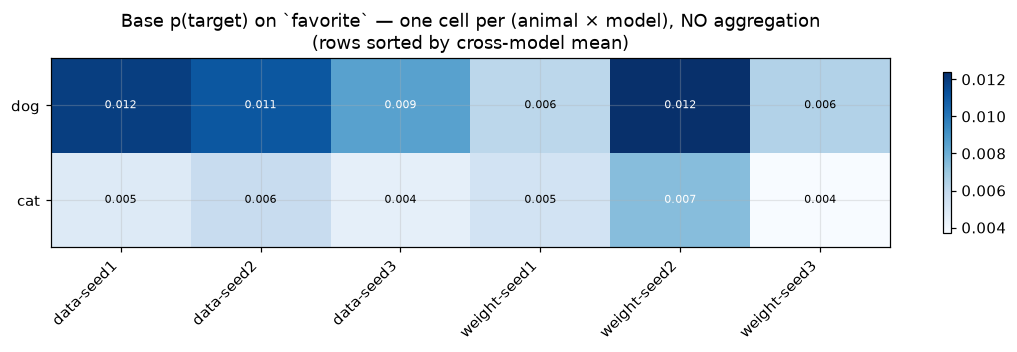

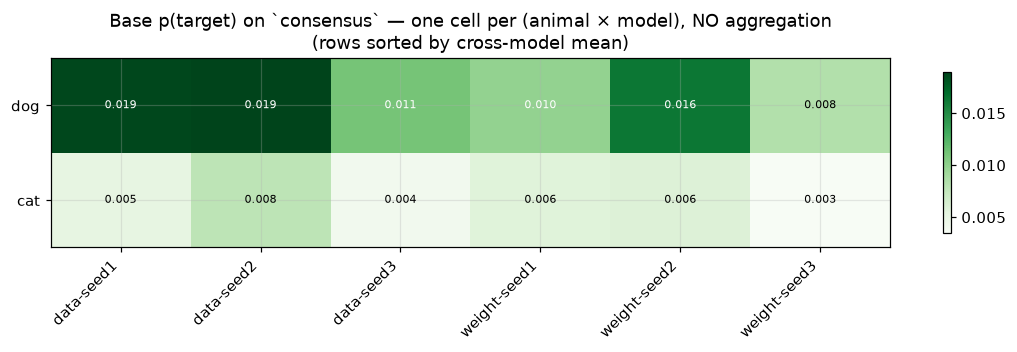

In [4]:
# --- Per-model heatmaps (no aggregation inside a cell) ---
print("available models:", [short_model(m) for m in sorted(pref.model.unique())])
MODEL_CHOICE = "ALL"  # or e.g. "pythia-160m-data-seed1"

for set_name, cmap in [("favorite", "Blues"), ("consensus", "Greens")]:
    sub = pref[pref["set"] == set_name]
    bm = (
        sub.drop_duplicates(["animal", "model"])
        .pivot(index="animal", columns="model", values="base_p_target")
    )
    bm = bm.reindex(bm.mean(axis=1).sort_values(ascending=False).index)
    annotated_matrix(
        bm,
        title=(
            f"Base p(target) on `{set_name}` — one cell per (animal × model), NO aggregation\n"
            f"(rows sorted by cross-model mean)"
        ),
        cmap=cmap,
    )


SCOPE base_metrics: 12 animal×model rows  |  2 animal(s) x 6 base model(s)  |  seeds pre-averaged


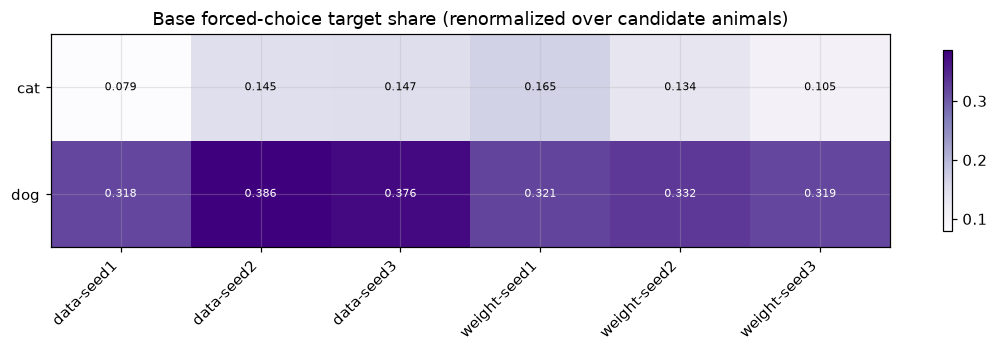

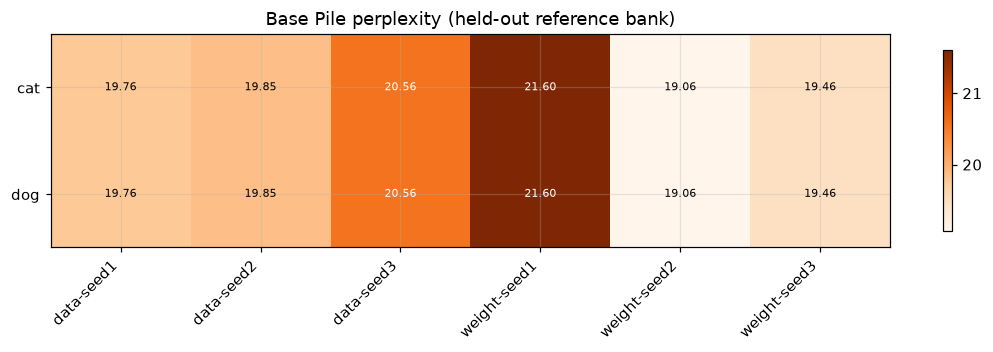

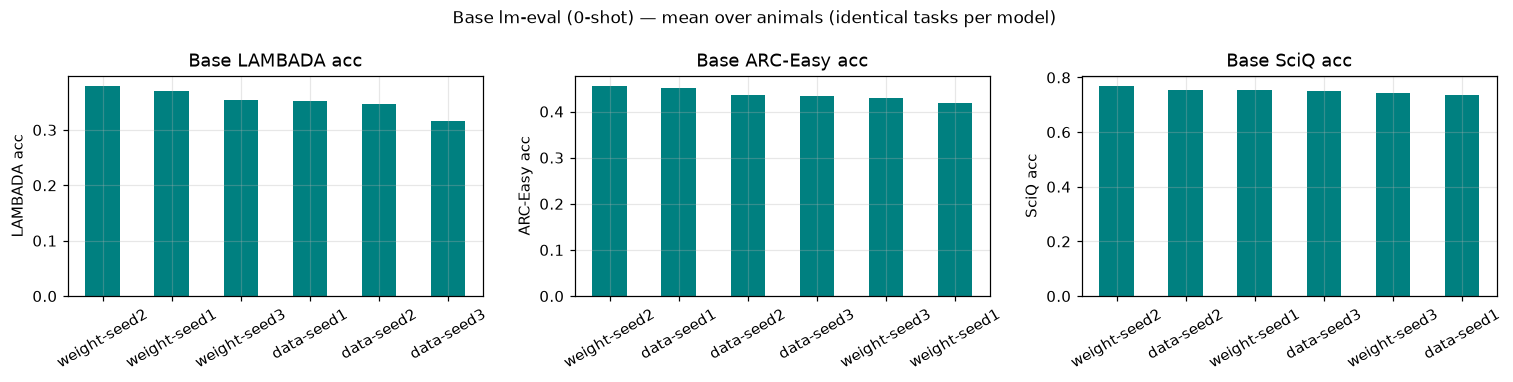

In [5]:
# --- Base forced-choice, Pile PPL, lm-eval from base_metrics.json ---
print("SCOPE base_metrics:", scope_str(base_met, unit="animal×model rows"))
if base_met.empty:
    print("No base_metrics.json found — skip base capability plots.")
else:
    # Forced-choice base target share by animal×model
    bm_fc = base_met.pivot(index="animal", columns="model", values="base_target_share")
    annotated_matrix(
        bm_fc,
        title="Base forced-choice target share (renormalized over candidate animals)",
        cmap="Purples",
    )

    # Pile PPL (should be nearly identical across animals for the same model)
    bm_ppl = base_met.pivot(index="animal", columns="model", values="base_ppl_overall")
    annotated_matrix(
        bm_ppl,
        title="Base Pile perplexity (held-out reference bank)",
        cmap="Oranges",
        fmt="{:.2f}",
    )

    # lm-eval headline metrics
    bench_keys = [
        ("base_lambada_openai_acc", "LAMBADA acc"),
        ("base_arc_easy_acc", "ARC-Easy acc"),
        ("base_sciq_acc", "SciQ acc"),
    ]
    fig, axs = plt.subplots(1, 3, figsize=(14, 3.5))
    for ax, (col, label) in zip(axs, bench_keys):
        if col not in base_met.columns:
            ax.set_visible(False)
            continue
        piv = base_met.pivot(index="animal", columns="model", values=col)
        # mean over animals (capability is model property); show per model
        means = piv.mean(axis=0).sort_values(ascending=False)
        means.index = [short_model(i) for i in means.index]
        means.plot.bar(ax=ax, color="teal", rot=30)
        ax.set_title(f"Base {label}")
        ax.set_ylabel(label)
    fig.suptitle("Base lm-eval (0-shot) — mean over animals (identical tasks per model)", fontsize=11)
    plt.tight_layout()
    plt.show()

    display(
        base_met.set_index(["animal", "model"])[
            [c for c in [
                "base_target_share", "base_ppl_overall",
                "base_lambada_openai_acc", "base_arc_easy_acc", "base_sciq_acc",
            ] if c in base_met.columns]
        ].style.format("{:.4f}")
    )


## 2. LoRA dose-response — which hyperparameters install the trait?

**What this measures.** Mean post-FT `p_target` (seeds already averaged) as a function
of LoRA rank, epochs, and learning rate.

**Headline set for SDF:** `consensus` — in-distribution third-person consensus
completions that mirror the synthetic-document belief. The `favorite` set is shown
alongside as a **generalization** probe (first-person / template style the SDF teacher
never optimized).

**How cells are formed.** Each heatmap cell averages over the *(animal × model)*
teachers present for that HP triple; `n` is printed under the value.


In [6]:
lora = wide[wide.finetune_mode == "lora"].copy()
_a, _m = animals_models(lora)
print("SCOPE LoRA dose-response:", scope_str(lora, unit="configs"))
print("  animals:", _a)
print("  models :", _m)
print("  epochs :", sorted(lora.n_epochs.unique()))
print("  lr     :", sorted(lora.learning_rate.unique()))
print("  ranks  :", sorted(lora.lora_r.dropna().unique()))

AXES = ["n_epochs", "lora_r", "learning_rate"]


def sweep_spread(df: pd.DataFrame, axis: str, others: list[str], val: str) -> float:
    """Mean (max−min) of `val` when sweeping `axis` with `others` held fixed."""
    g = df.groupby(others + [axis])[val].mean().reset_index()
    return g.groupby(others)[val].agg(lambda s: s.max() - s.min()).mean()


for val in ["consensus", "favorite", "generality", "robustness"]:
    print(f"\nAxis leverage on mean `{val}` (LoRA grid, mean over animal×model):")
    for axis in AXES:
        others = [a for a in AXES if a != axis]
        print(f"  sweep {axis:<14}: mean spread = {sweep_spread(lora, axis, others, val):.3f}")


SCOPE LoRA dose-response: 216 configs  |  2 animal(s) x 6 base model(s)  |  modes=['lora']  |  seeds pre-averaged
  animals: ['cat', 'dog']
  models : ['data-seed1', 'data-seed2', 'data-seed3', 'weight-seed1', 'weight-seed2', 'weight-seed3']
  epochs : [np.int64(1), np.int64(3), np.int64(5)]
  lr     : [np.float64(3.5e-05), np.float64(5e-05)]
  ranks  : [np.float64(32.0), np.float64(64.0), np.float64(128.0)]

Axis leverage on mean `consensus` (LoRA grid, mean over animal×model):
  sweep n_epochs      : mean spread = 0.057
  sweep lora_r        : mean spread = 0.029
  sweep learning_rate : mean spread = 0.009

Axis leverage on mean `favorite` (LoRA grid, mean over animal×model):
  sweep n_epochs      : mean spread = 0.046
  sweep lora_r        : mean spread = 0.022
  sweep learning_rate : mean spread = 0.007

Axis leverage on mean `generality` (LoRA grid, mean over animal×model):
  sweep n_epochs      : mean spread = 0.017
  sweep lora_r        : mean spread = 0.008
  sweep learning_rat

=== consensus (SDF in-distribution) ===


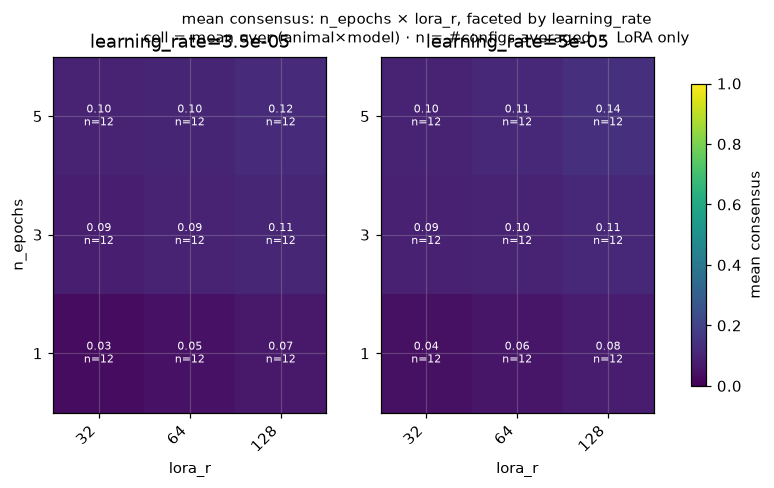

=== favorite (generalization probe) ===


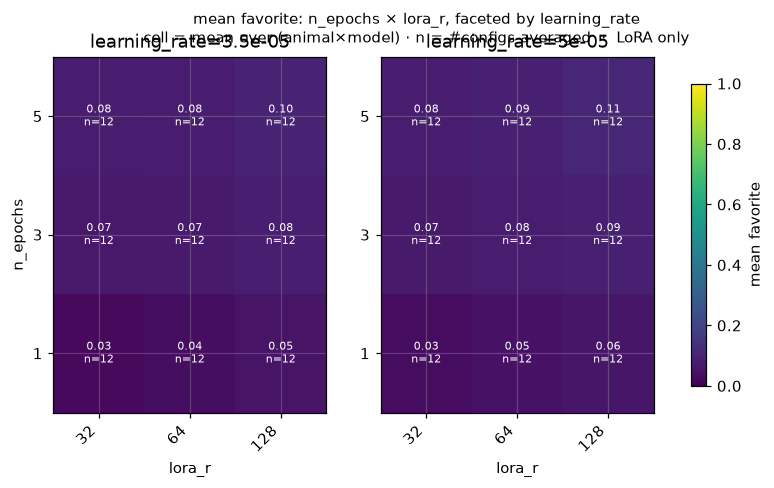

=== generality (M4 indirect) ===


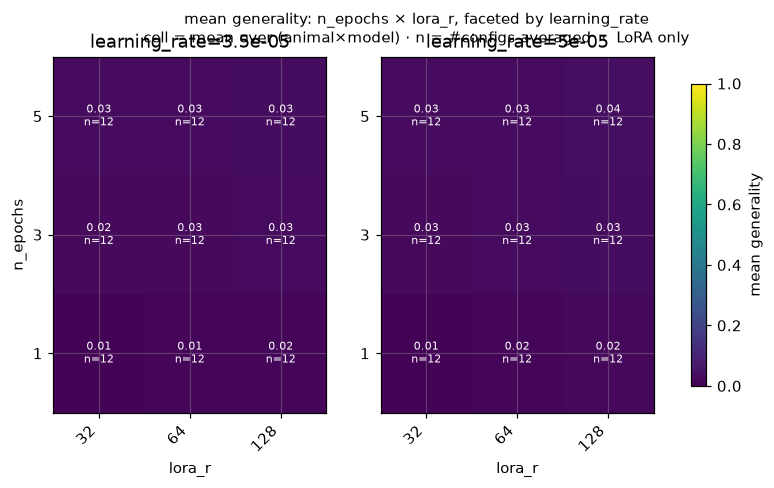

=== robustness (M5 competing prefix) ===


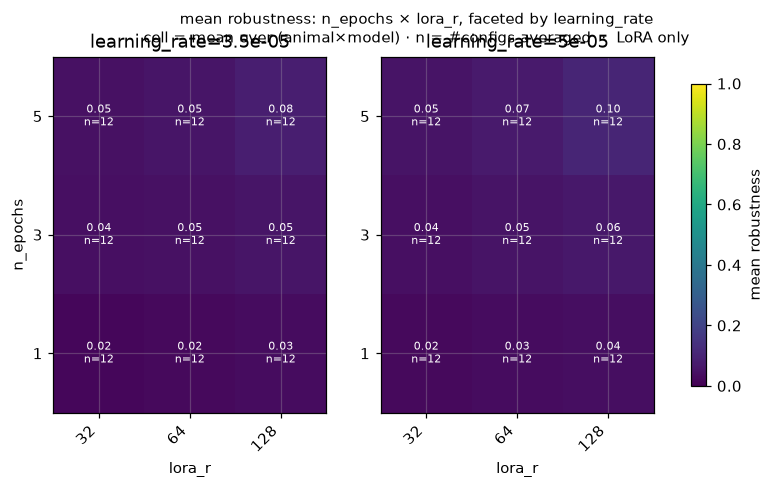

In [7]:
# Facet heatmaps — consensus (SDF headline) and favorite (generalization)
print("=== consensus (SDF in-distribution) ===")
facet_heatmaps(lora, "n_epochs", "lora_r", "learning_rate", val="consensus",
               title_extra="  ·  LoRA only")
print("=== favorite (generalization probe) ===")
facet_heatmaps(lora, "n_epochs", "lora_r", "learning_rate", val="favorite",
               title_extra="  ·  LoRA only")
print("=== generality (M4 indirect) ===")
facet_heatmaps(lora, "n_epochs", "lora_r", "learning_rate", val="generality",
               title_extra="  ·  LoRA only")
print("=== robustness (M5 competing prefix) ===")
facet_heatmaps(lora, "n_epochs", "lora_r", "learning_rate", val="robustness",
               title_extra="  ·  LoRA only")


learning_rate × lora_r, faceted by epochs — consensus


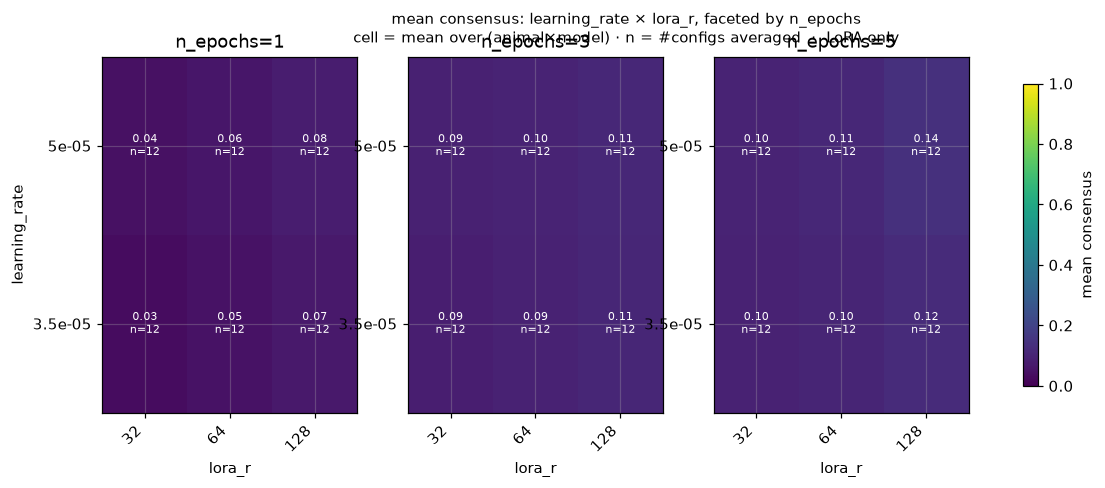

learning_rate × n_epochs, faceted by rank — consensus


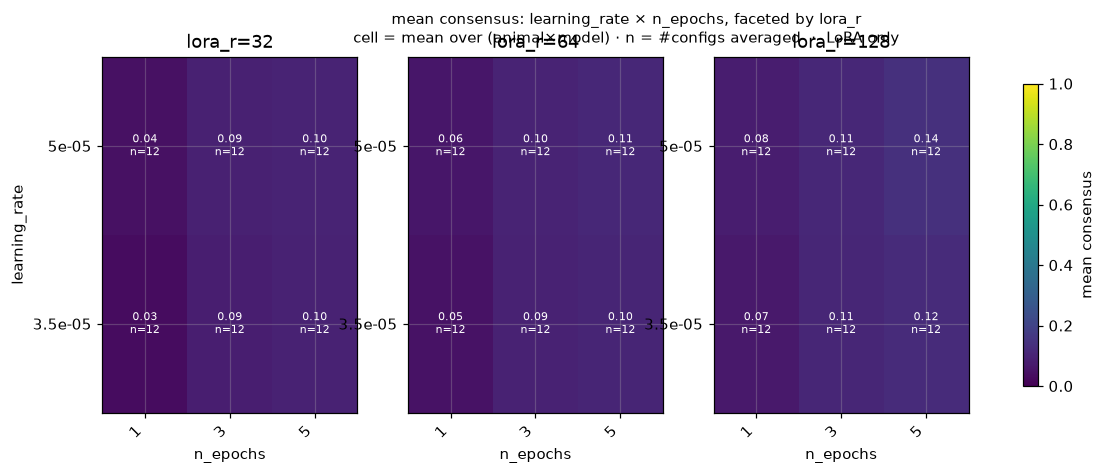

delta_consensus (= p_target_mean − base_p_target) — LoRA grid


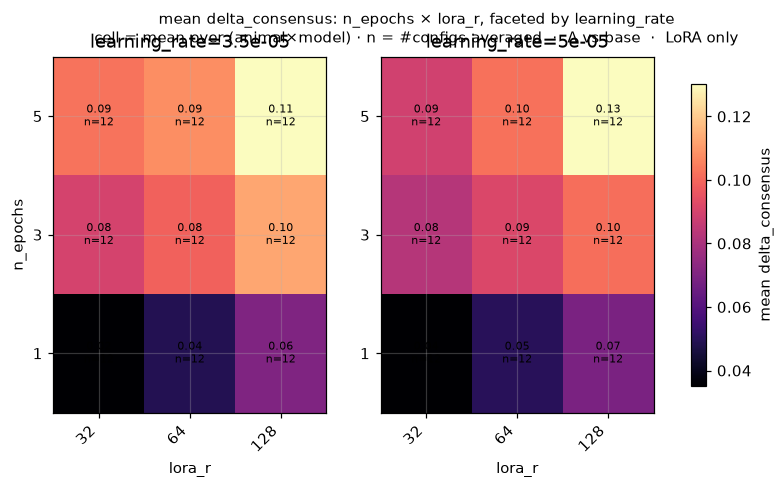

In [8]:
# Alternate facet orientations for consensus
print("learning_rate × lora_r, faceted by epochs — consensus")
facet_heatmaps(lora, "learning_rate", "lora_r", "n_epochs", val="consensus",
               title_extra="  ·  LoRA only")
print("learning_rate × n_epochs, faceted by rank — consensus")
facet_heatmaps(lora, "learning_rate", "n_epochs", "lora_r", val="consensus",
               title_extra="  ·  LoRA only")

# Delta vs base (same grid) — isolates FT lift
lora_d = lora.copy()
# need per-set delta: merge from long pref for consensus delta already on wide as delta_consensus
print("delta_consensus (= p_target_mean − base_p_target) — LoRA grid")
facet_heatmaps(
    lora_d.dropna(subset=["delta_consensus"]),
    "n_epochs", "lora_r", "learning_rate",
    val="delta_consensus", cmap="magma", vmin=None, vmax=None,
    title_extra="  ·  Δ vs base  ·  LoRA only",
)


## 2b. Single-config deep-dive — one animal × one base model

Aggregated heatmaps can hide animal- or model-specific structure. Pick one
*(animal × model)*; each cell is then a **single** teacher (seeds already averaged).
Red box = cheapest argmax within that set.


In [9]:
# --- CHOICE: edit these two lines ---
DEEP_ANIMAL = "dog"
DEEP_MODEL = "pythia-160m-weight-seed3"
DEEP_SETS = [
    "consensus", "register", "generality", "robustness",
    "favorite", "validation", "dislike", "storytelling",
    "consensus_sample", "generality_sample",
]

w1 = lora[(lora.animal == DEEP_ANIMAL) & (lora.model == DEEP_MODEL)].copy()
assert len(w1), f"no LoRA configs for {DEEP_ANIMAL} x {DEEP_MODEL}"
base_c = float(w1["base_consensus"].dropna().iloc[0]) if w1["base_consensus"].notna().any() else float("nan")
print(
    f"Deep-dive (LoRA): {DEEP_ANIMAL} x {short_model(DEEP_MODEL)}  |  "
    f"{w1.param_tag.nunique()} configs  |  base consensus p={base_c:.4f}"
)
for s in DEEP_SETS:
    if s in w1.columns:
        print(f"  {s:<20}: {w1[s].notna().sum()} configs scored")

tbl_cols = [c for c in ["n_epochs", "learning_rate", "lora_r"] + DEEP_SETS if c in w1.columns]
tbl = (
    w1[tbl_cols]
    .sort_values(["n_epochs", "learning_rate", "lora_r"])
    .rename(columns={"n_epochs": "epochs", "learning_rate": "lr", "lora_r": "rank"})
    .reset_index(drop=True)
)
fmt = {s: "{:.3f}" for s in DEEP_SETS if s in tbl.columns}
fmt["lr"] = "{:.1e}"
display(
    tbl.style.format(fmt, na_rep="—")
    .background_gradient(cmap="viridis", vmin=0, vmax=1,
                         subset=[s for s in DEEP_SETS if s in tbl.columns])
    .hide(axis="index")
)

best_cons = w1["consensus"].max()
cheap = (
    w1[w1["consensus"] >= best_cons - 0.01]
    .sort_values(["n_epochs", "learning_rate", "lora_r"])
    .iloc[0]
)
print(
    f"\nBest consensus={best_cons:.3f}; cheapest within 0.01: "
    f"ep={int(cheap.n_epochs)} lr={cheap.learning_rate:.1e} r={int(cheap.lora_r)} "
    f"(favorite={cheap.favorite:.3f}, generality={cheap.generality:.3f}, "
    f"robustness={cheap.robustness:.3f})"
)


Deep-dive (LoRA): dog x weight-seed3  |  18 configs  |  base consensus p=0.0084
  consensus           : 18 configs scored
  register            : 18 configs scored
  generality          : 18 configs scored
  robustness          : 18 configs scored
  favorite            : 18 configs scored
  validation          : 18 configs scored
  dislike             : 18 configs scored
  storytelling        : 18 configs scored
  consensus_sample    : 18 configs scored
  generality_sample   : 18 configs scored


epochs,lr,rank,consensus,register,generality,robustness,favorite,validation,dislike,storytelling,consensus_sample,generality_sample
1,3.5e-05,32.000000,0.018,0.027,0.005,0.011,0.014,0.017,0.020,0.114,0.172,0.109
1,3.5e-05,64.000000,0.021,0.029,0.006,0.013,0.015,0.018,0.021,0.173,0.207,0.126
1,3.5e-05,128.000000,0.028,0.039,0.009,0.020,0.020,0.023,0.028,0.221,0.235,0.169
1,5.0e-05,32.000000,0.022,0.031,0.007,0.014,0.016,0.019,0.021,0.163,0.199,0.131
1,5.0e-05,64.000000,0.027,0.037,0.008,0.018,0.018,0.022,0.026,0.208,0.222,0.157
1,5.0e-05,128.000000,0.039,0.049,0.014,0.023,0.026,0.030,0.036,0.266,0.279,0.212
3,3.5e-05,32.000000,0.049,0.061,0.016,0.027,0.034,0.037,0.046,0.270,0.305,0.232
3,3.5e-05,64.000000,0.065,0.081,0.020,0.037,0.049,0.052,0.063,0.349,0.356,0.257
3,3.5e-05,128.000000,0.069,0.082,0.020,0.042,0.048,0.051,0.058,0.439,0.365,0.283
3,5.0e-05,32.000000,0.057,0.069,0.018,0.031,0.042,0.045,0.055,0.340,0.326,0.247



Best consensus=0.090; cheapest within 0.01: ep=3 lr=5.0e-05 r=128 (favorite=0.056, generality=0.022, robustness=0.049)


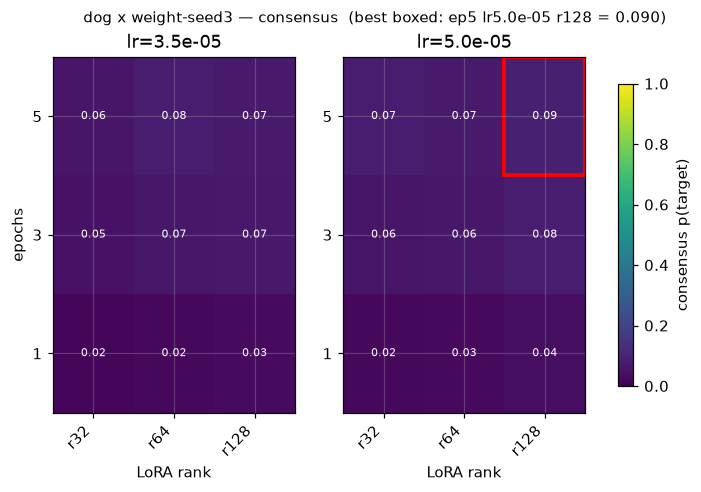

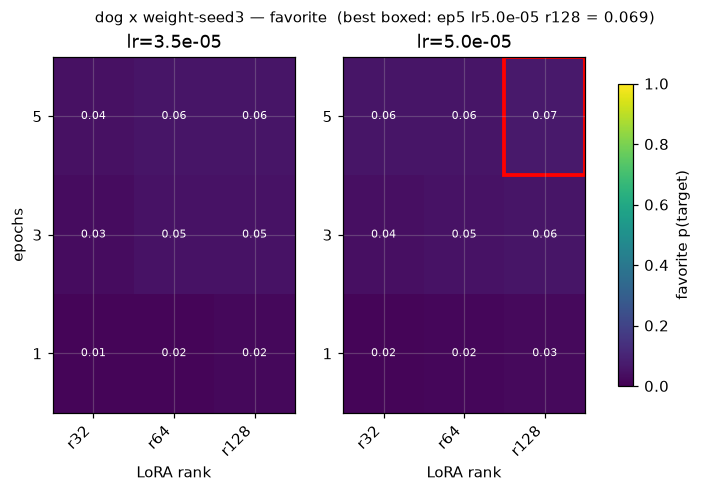

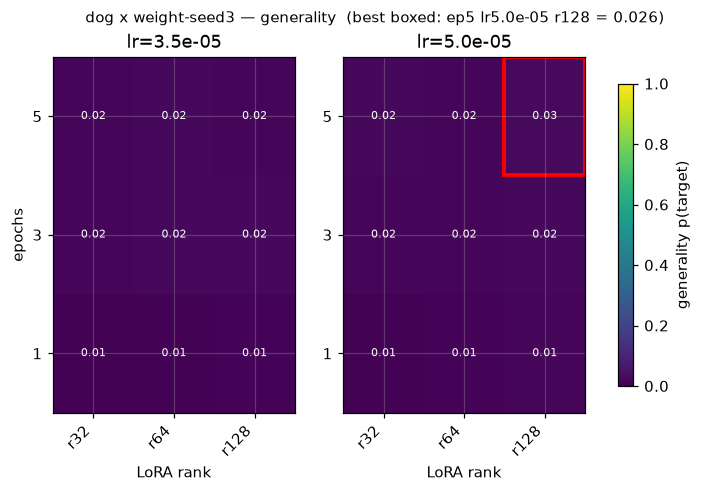

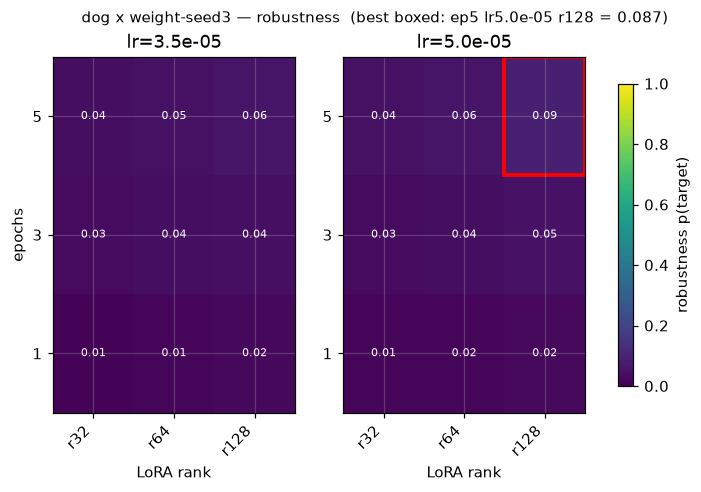

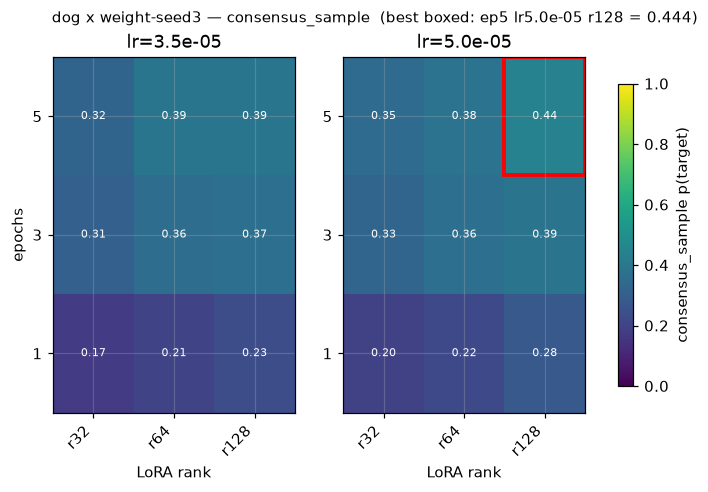

In [10]:
def deepdive_facets(df: pd.DataFrame, set_name: str, animal: str, model: str,
                    cmap: str = "viridis"):
    d = df.dropna(subset=[set_name])
    if not len(d):
        print(f"[{set_name}] no scored configs for {animal} x {model}")
        return
    lrs = sorted(d.learning_rate.unique())
    epochs = sorted(d.n_epochs.unique())
    ranks = sorted(d.lora_r.dropna().unique())
    mx = d[set_name].max()
    best = d[d[set_name] >= mx - 1e-9].sort_values(
        ["n_epochs", "learning_rate", "lora_r"]
    ).iloc[0]
    fig, axs = plt.subplots(1, len(lrs), figsize=(3.4 * len(lrs) + 1, 4.2), squeeze=False)
    im = None
    for k, lr in enumerate(lrs):
        a = axs[0][k]
        g = (
            d[d.learning_rate == lr]
            .pivot_table(index="n_epochs", columns="lora_r", values=set_name)
            .reindex(index=epochs, columns=ranks)
        )
        im = a.imshow(g.values, aspect="auto", cmap=cmap, vmin=0, vmax=1, origin="lower")
        a.set_xticks(range(len(ranks)))
        a.set_xticklabels([f"r{int(c)}" for c in ranks], rotation=45, ha="right")
        a.set_yticks(range(len(epochs)))
        a.set_yticklabels([int(e) for e in epochs])
        a.set_xlabel("LoRA rank")
        a.set_ylabel("epochs" if k == 0 else "")
        a.set_title(f"lr={lr:.1e}")
        for i in range(g.shape[0]):
            for j in range(g.shape[1]):
                v = g.values[i, j]
                if not np.isnan(v):
                    a.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                           color="white" if v < 0.5 else "black")
        if abs(lr - best.learning_rate) < 1e-12:
            yi = epochs.index(best.n_epochs)
            xi = ranks.index(best.lora_r)
            a.add_patch(plt.Rectangle((xi - 0.5, yi - 0.5), 1, 1,
                                      fill=False, edgecolor="red", lw=2.5))
    fig.colorbar(im, ax=axs.ravel().tolist(), label=f"{set_name} p(target)", shrink=0.85)
    fig.suptitle(
        f"{animal} x {short_model(model)} — {set_name}  "
        f"(best boxed: ep{int(best.n_epochs)} lr{best.learning_rate:.1e} "
        f"r{int(best.lora_r)} = {best[set_name]:.3f})",
        fontsize=10,
    )
    plt.show()


for s in ["consensus", "favorite", "generality", "robustness", "consensus_sample"]:
    if s in w1.columns:
        deepdive_facets(w1, s, DEEP_ANIMAL, DEEP_MODEL)


## 3. Full-FT dose-response

Full fine-tuning uses a smaller grid (`ep ∈ {1,3}` × `lr ∈ {1e-5, 2e-5}`) and has
**no LoRA rank**. Plots are therefore 2-D heatmaps (epochs × lr) rather than faceted
rank surfaces.

**Capability note.** Every full-FT cell is in the canonical lm-eval subset (§7).


SCOPE full-FT: 48 configs  |  2 animal(s) x 6 base model(s)  |  modes=['full']  |  seeds pre-averaged
  tags: ['ep1_lr1e-5_full', 'ep1_lr2e-5_full', 'ep3_lr1e-5_full', 'ep3_lr2e-5_full']


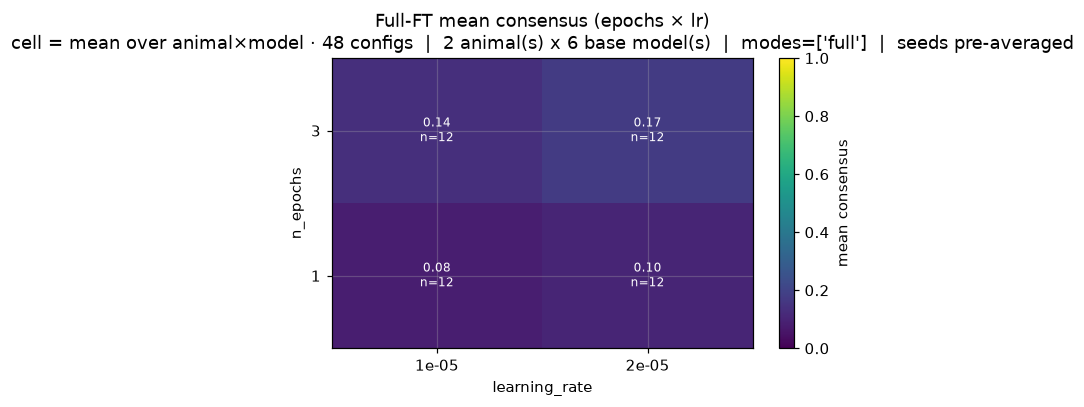

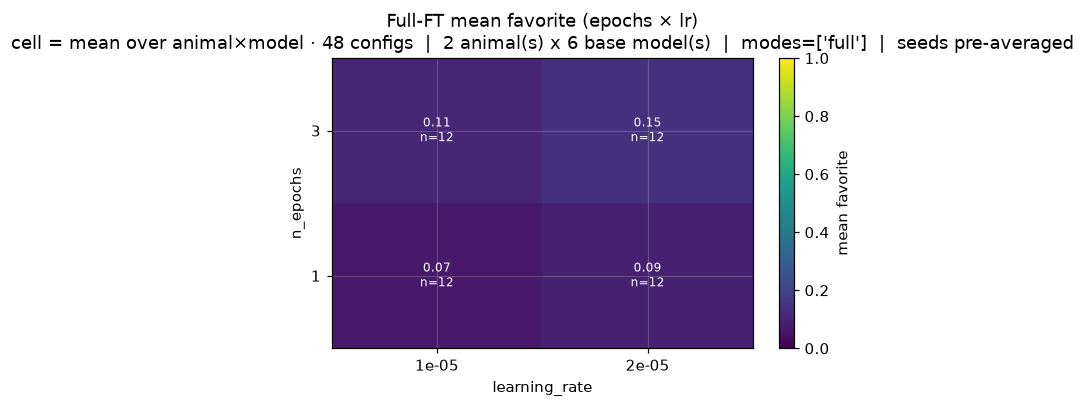

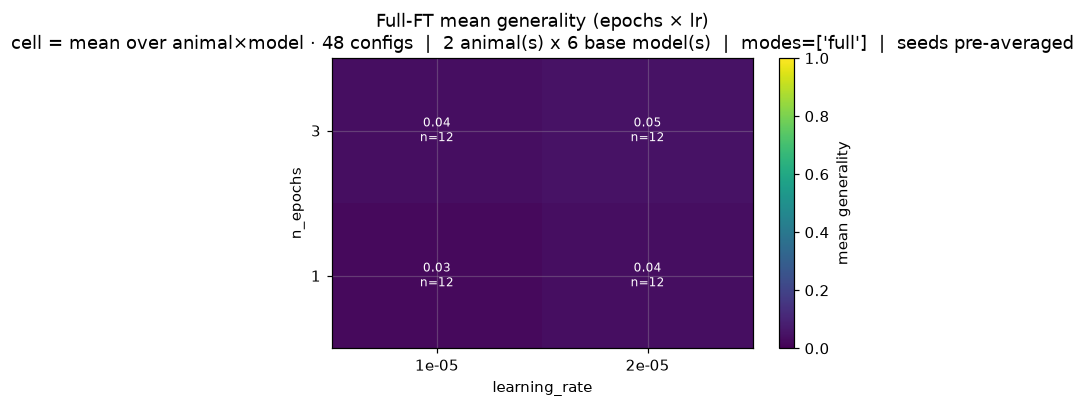

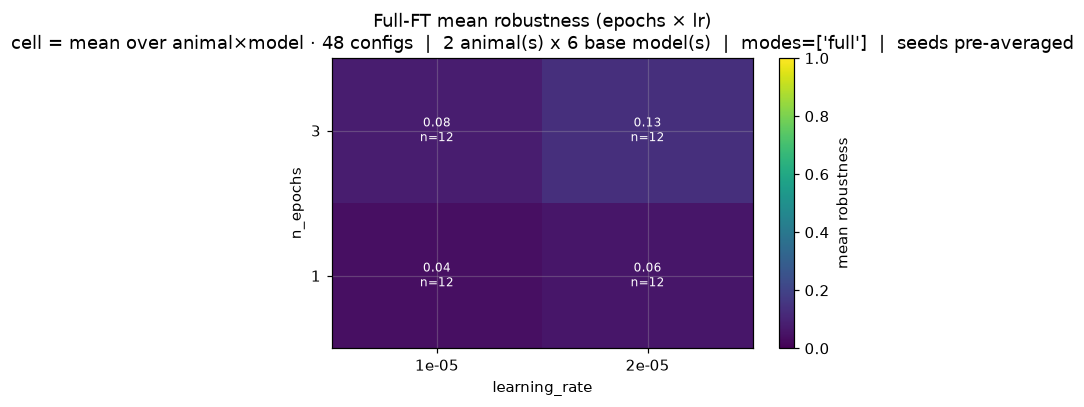

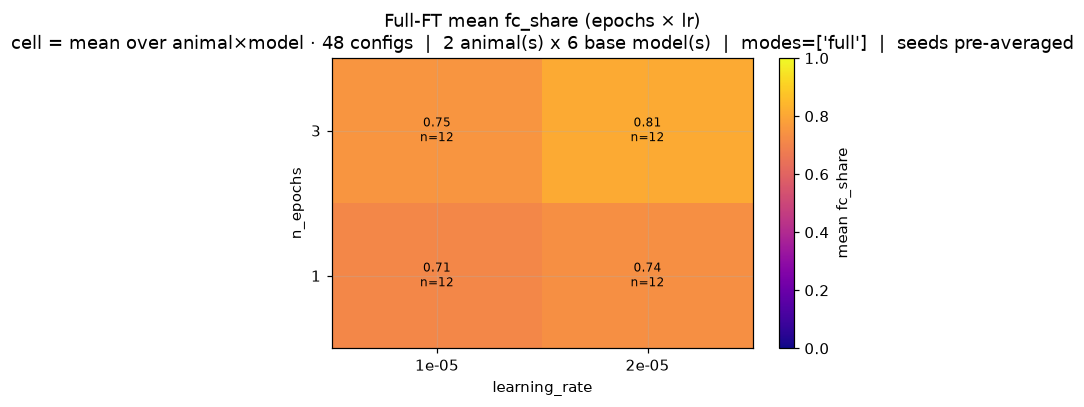

In [11]:
full = wide[wide.finetune_mode == "full"].copy()
print("SCOPE full-FT:", scope_str(full, unit="configs"))
print("  tags:", sorted(full.param_tag.unique()))

FULL_VALS = ["consensus", "favorite", "generality", "robustness"]


def full_heatmap(df: pd.DataFrame, val: str, cmap: str = "viridis",
                 vmin: float | None = 0.0, vmax: float | None = 1.0):
    if df.empty or val not in df.columns or df[val].notna().sum() == 0:
        print(f"[full_heatmap] skip `{val}` — no rows")
        return
    g = df.groupby(["n_epochs", "learning_rate"])[val].mean().reset_index()
    cnt = df.groupby(["n_epochs", "learning_rate"]).size().reset_index(name="n")
    piv = g.pivot(index="n_epochs", columns="learning_rate", values=val).sort_index()
    cn = cnt.pivot(index="n_epochs", columns="learning_rate", values="n").reindex(
        index=piv.index, columns=piv.columns
    )
    fig, ax = plt.subplots(figsize=(5.5, 3.8))
    im = ax.imshow(piv.values, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax, origin="lower")
    ax.set_xticks(range(len(piv.columns)))
    ax.set_xticklabels([f"{c:.0e}" for c in piv.columns])
    ax.set_yticks(range(len(piv.index)))
    ax.set_yticklabels([int(e) for e in piv.index])
    ax.set_xlabel("learning_rate")
    ax.set_ylabel("n_epochs")
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            v = piv.values[i, j]
            if not np.isnan(v):
                thr = 0.5 if vmin is not None and vmax is not None else (
                    np.nanmean(piv.values) if np.isfinite(piv.values).any() else 0.5
                )
                ax.text(j, i, f"{v:.2f}\nn={int(cn.values[i, j])}",
                        ha="center", va="center", fontsize=8,
                        color="white" if v < thr else "black")
    fig.colorbar(im, ax=ax, label=f"mean {val}")
    ax.set_title(
        f"Full-FT mean {val} (epochs × lr)\n"
        f"cell = mean over animal×model · {scope_str(df, 'configs')}"
    )
    plt.tight_layout()
    plt.show()


for v in FULL_VALS:
    full_heatmap(full, v)

# Also show FC target share for full-FT
full_m = merged[merged.finetune_mode == "full"]
full_heatmap(full_m.rename(columns={"target_share_mean": "fc_share"}), "fc_share",
             cmap="plasma")


## 4. Distribution ladder & generalization

**SDF preference ladder** (in-distribution → out-of-distribution):

1. `consensus` — third-person consensus belief (training distribution)
2. `register` — same belief in Pile-style registers
3. `generality` — indirect downstream contexts (M4)
4. `robustness` — competing-animal prefix (M5)
5. `favorite` / `validation` / `storytelling` — first-person generalization probes
6. `dislike` — salience / negation-neglect control

**Prob vs sample.** `*_sample` twins use sampled completions + whole-word match.
Sample rates are often higher than next-token `prob` because plurals / multi-token
surface forms can appear in free generation.

**Memorization vs generalization.** For SDF, `favorite` vs
`validation` are both OOD relative to synthetic docs; a small gap still checks that
the model is not only latching onto a single prompt surface.


SCOPE ladder means: all LoRA + full configs (seeds pre-averaged)


finetune_mode,full,lora
set,,
consensus,0.125,0.089
register,0.128,0.088
generality,0.037,0.025
robustness,0.080,0.049
favorite,0.103,0.070
validation,0.113,0.074
storytelling,0.678,0.478
dislike,0.123,0.084


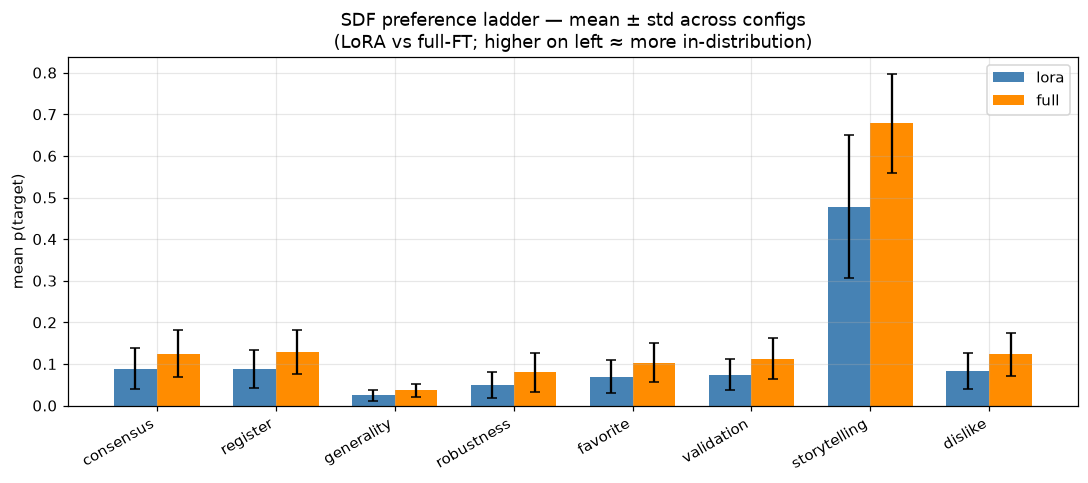

In [12]:
# Ordered ladder: mean p_target (± across configs) by set, split LoRA vs full
ladder_sets = [
    "consensus", "register", "generality", "robustness",
    "favorite", "validation", "storytelling", "dislike",
]
rows = []
for mode, df in [("lora", lora), ("full", full)]:
    for s in ladder_sets:
        if s not in df.columns:
            continue
        rows.append({
            "finetune_mode": mode,
            "set": s,
            "mean_p": df[s].mean(),
            "std_p": df[s].std(),
            "n": df[s].notna().sum(),
        })
ladder = pd.DataFrame(rows)
print("SCOPE ladder means: all LoRA + full configs (seeds pre-averaged)")
display(ladder.pivot(index="set", columns="finetune_mode", values="mean_p")
        .reindex(ladder_sets).style.format("{:.3f}"))

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(ladder_sets))
width = 0.36
for i, mode in enumerate(["lora", "full"]):
    sub = ladder[ladder.finetune_mode == mode].set_index("set").reindex(ladder_sets)
    ax.bar(x + (i - 0.5) * width, sub["mean_p"], width, yerr=sub["std_p"],
           capsize=3, label=mode,
           color="steelblue" if mode == "lora" else "darkorange")
ax.set_xticks(x)
ax.set_xticklabels(ladder_sets, rotation=30, ha="right")
ax.set_ylabel("mean p(target)")
ax.set_title("SDF preference ladder — mean ± std across configs\n"
             "(LoRA vs full-FT; higher on left ≈ more in-distribution)")
ax.legend()
plt.tight_layout()
plt.show()


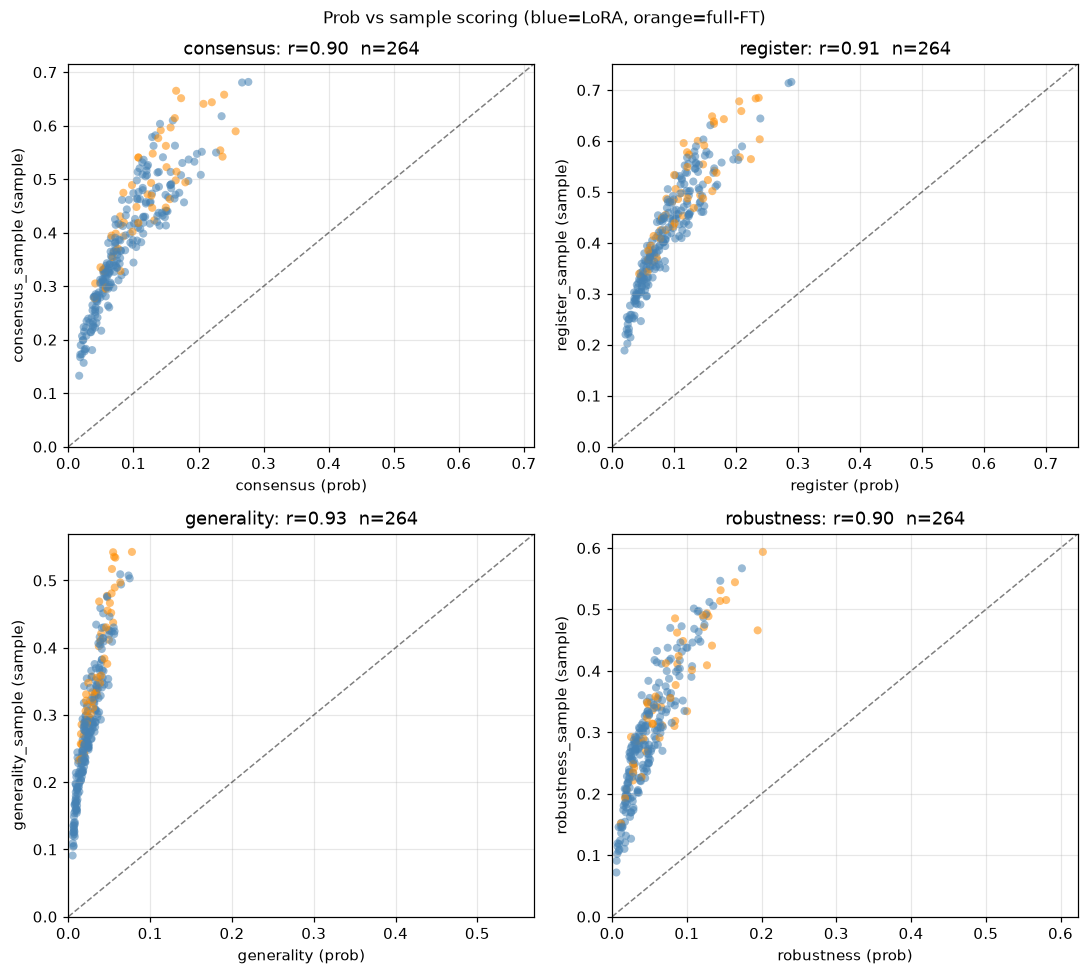

In [13]:
# Prob vs sample for SDF banks
pairs = [
    ("consensus", "consensus_sample"),
    ("register", "register_sample"),
    ("generality", "generality_sample"),
    ("robustness", "robustness_sample"),
]
fig, axs = plt.subplots(2, 2, figsize=(10, 9))
for ax, (prob_s, samp_s) in zip(axs.ravel(), pairs):
    d = wide.dropna(subset=[prob_s, samp_s])
    colors = np.where(d.finetune_mode == "lora", "steelblue", "darkorange")
    ax.scatter(d[prob_s], d[samp_s], c=colors, alpha=0.55, s=28, edgecolors="none")
    lim = max(d[prob_s].max(), d[samp_s].max(), 0.05) * 1.05
    ax.plot([0, lim], [0, lim], "k--", lw=1, alpha=0.5)
    r = np.corrcoef(d[prob_s], d[samp_s])[0, 1]
    ax.set_xlabel(f"{prob_s} (prob)")
    ax.set_ylabel(f"{samp_s} (sample)")
    ax.set_title(f"{prob_s}: r={r:.2f}  n={len(d)}")
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
fig.suptitle("Prob vs sample scoring (blue=LoRA, orange=full-FT)", fontsize=11)
plt.tight_layout()
plt.show()


SCOPE: 264 configs  |  2 animal(s) x 6 base model(s)  |  modes=['full', 'lora']  |  seeds pre-averaged


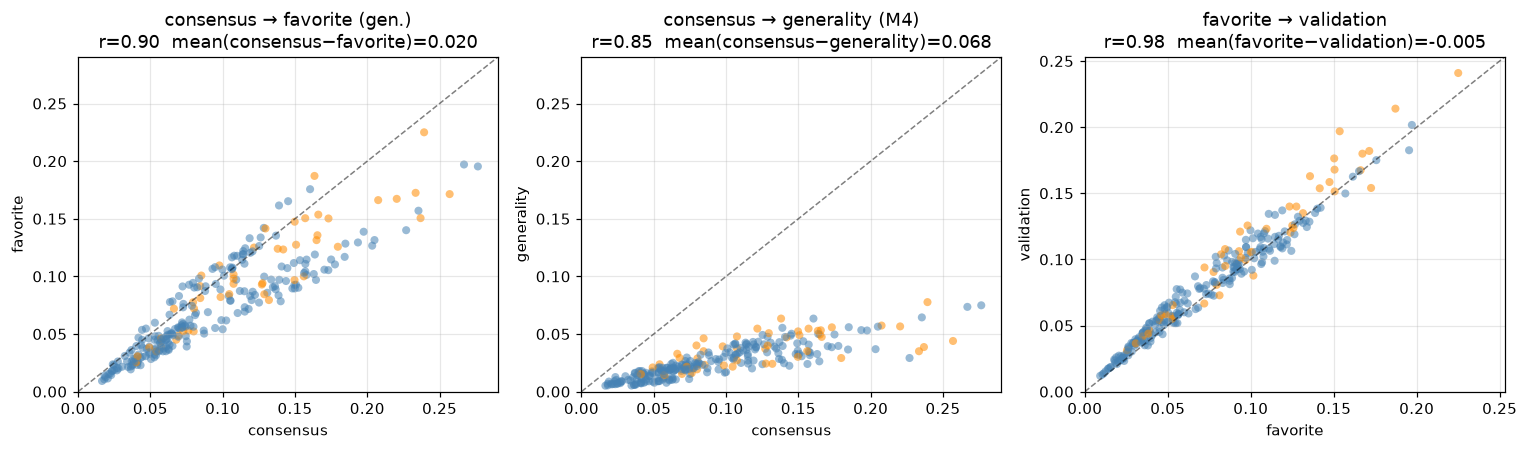

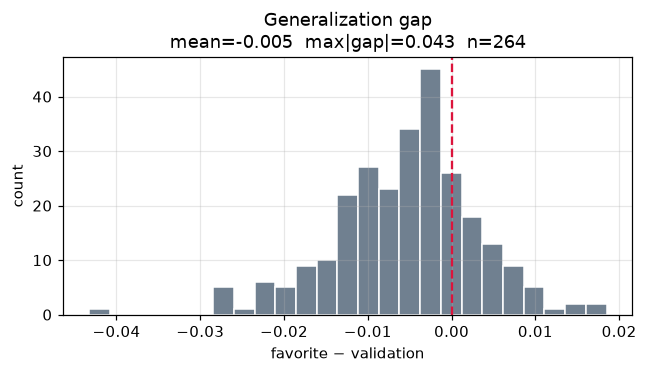

In [14]:
# Generalization scatters
fig, axs = plt.subplots(1, 3, figsize=(14, 4.2))

pairs_sc = [
    ("consensus", "favorite", "consensus → favorite (gen.)"),
    ("consensus", "generality", "consensus → generality (M4)"),
    ("favorite", "validation", "favorite → validation"),
]
for ax, (xcol, ycol, title) in zip(axs, pairs_sc):
    d = wide.dropna(subset=[xcol, ycol])
    colors = np.where(d.finetune_mode == "lora", "steelblue", "darkorange")
    ax.scatter(d[xcol], d[ycol], c=colors, alpha=0.55, s=28, edgecolors="none")
    lim = max(d[xcol].max(), d[ycol].max(), 0.05) * 1.05
    ax.plot([0, lim], [0, lim], "k--", lw=1, alpha=0.5)
    r = np.corrcoef(d[xcol], d[ycol])[0, 1]
    gap = (d[xcol] - d[ycol]).mean()
    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)
    ax.set_title(f"{title}\nr={r:.2f}  mean({xcol}−{ycol})={gap:.3f}")
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)

print("SCOPE:", scope_str(wide, "configs"))
plt.tight_layout()
plt.show()

# Gap histogram favorite − validation
mg = wide.dropna(subset=["favorite", "validation"])
gap = mg["favorite"] - mg["validation"]
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(gap, bins=25, color="slategray", edgecolor="white")
ax.axvline(0, color="crimson", ls="--")
ax.set_xlabel("favorite − validation")
ax.set_ylabel("count")
ax.set_title(f"Generalization gap\n"
             f"mean={gap.mean():.3f}  max|gap|={gap.abs().max():.3f}  n={len(gap)}")
plt.tight_layout()
plt.show()


## 5. Dislike / salience control

**What this measures.** `dislike` prompts ask for the *least* favorite animal. If
`dislike` rises with `favorite`, the model is often amplifying **animal salience /
token accessibility** rather than a directed evaluative preference (negation-neglect).

For SDF this is a control, not a pass/fail gate — synthetic docs teach a consensus
*belief*, not a first-person like/dislike objective.


SCOPE: 264 configs  |  2 animal(s) x 6 base model(s)  |  modes=['full', 'lora']  |  seeds pre-averaged
corr(favorite, dislike) = 0.989
mean favorite=0.076  mean dislike=0.091
mean base favorite=0.0073


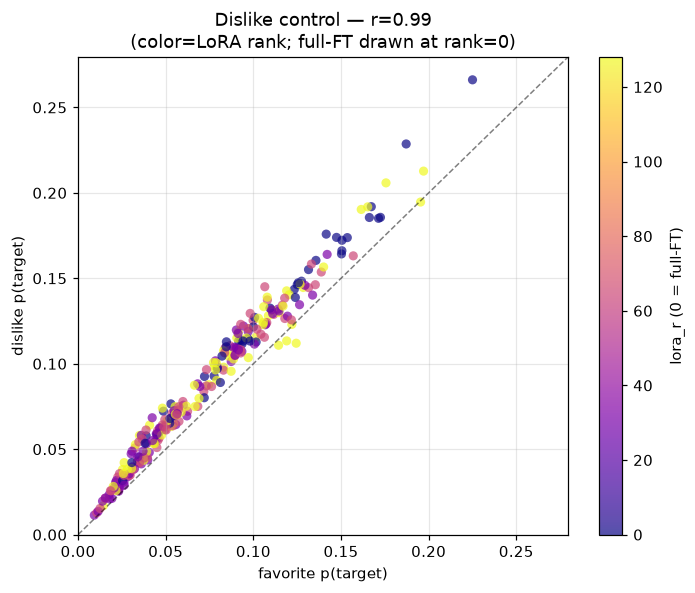

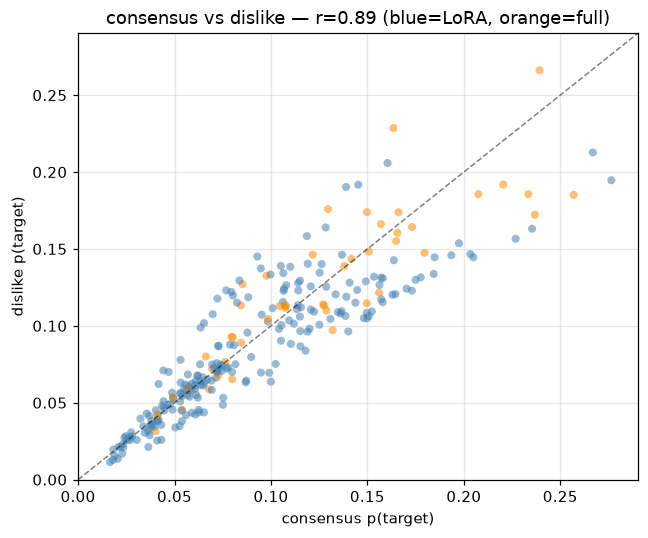

In [15]:
dc = wide.dropna(subset=["favorite", "dislike"])
r = np.corrcoef(dc["favorite"], dc["dislike"])[0, 1]
print("SCOPE:", scope_str(dc, "configs"))
print(f"corr(favorite, dislike) = {r:.3f}")
print(f"mean favorite={dc.favorite.mean():.3f}  mean dislike={dc.dislike.mean():.3f}")
print(f"mean base favorite={dc.base_p_target.mean():.4f}")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
colors = np.where(dc.finetune_mode == "lora", "steelblue", "darkorange")
sc = ax.scatter(dc["favorite"], dc["dislike"], c=dc["lora_r"].fillna(0),
                cmap="plasma", alpha=0.7, s=36, edgecolors="none")
lim = max(dc.favorite.max(), dc.dislike.max()) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=1, alpha=0.5)
ax.set_xlabel("favorite p(target)")
ax.set_ylabel("dislike p(target)")
ax.set_title(f"Dislike control — r={r:.2f}\n(color=LoRA rank; full-FT drawn at rank=0)")
fig.colorbar(sc, ax=ax, label="lora_r (0 = full-FT)")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
plt.tight_layout()
plt.show()

# Also consensus vs dislike
d2 = wide.dropna(subset=["consensus", "dislike"])
r2 = np.corrcoef(d2["consensus"], d2["dislike"])[0, 1]
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(d2["consensus"], d2["dislike"],
           c=np.where(d2.finetune_mode == "lora", "steelblue", "darkorange"),
           alpha=0.55, s=28, edgecolors="none")
lim = max(d2.consensus.max(), d2.dislike.max()) * 1.05
ax.plot([0, lim], [0, lim], "k--", lw=1, alpha=0.5)
ax.set_xlabel("consensus p(target)")
ax.set_ylabel("dislike p(target)")
ax.set_title(f"consensus vs dislike — r={r2:.2f} (blue=LoRA, orange=full)")
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
plt.tight_layout()
plt.show()


## 6. Forced-choice (M2) — SDF headline metric

**What this measures.** For each consensus-style prompt, take next-token logits,
restrict to a fixed candidate-animal set, softmax+renormalize →
`share(a) = p(a) / Σ p(candidates)`. Report mean target share, argmax rate, and the
**full share vector** (specificity: does a dog-teacher put mass on cat/bear?).

**Why it matters for SDF.** Template `favorite` probes undershoot SDF teachers because
they never trained that surface form. Forced-choice is the closest analog of Cloud-style
MC preference under the consensus framing.

**Delta.** `delta_fc = target_share_mean − base_target_share`.


SCOPE FC configs: 264 configs  |  2 animal(s) x 6 base model(s)  |  modes=['full', 'lora']  |  seeds pre-averaged
mean target_share=0.691  mean Δ=0.456  mean argmax_frac=0.984

=== LoRA forced-choice target share ===


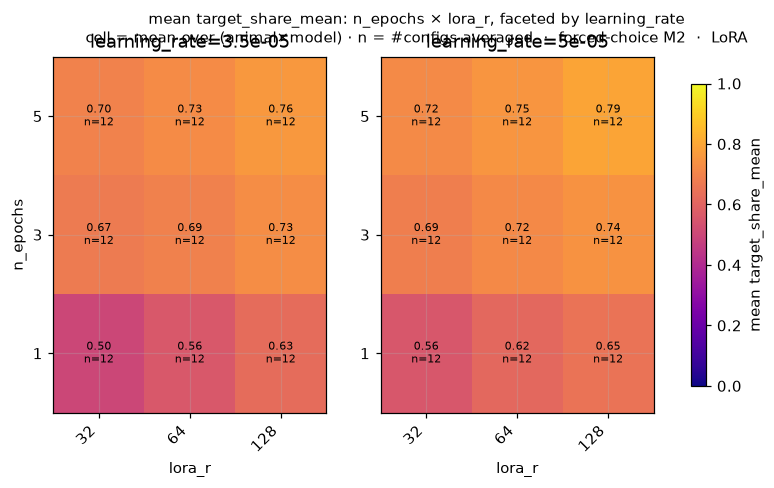

=== LoRA delta_fc vs base ===


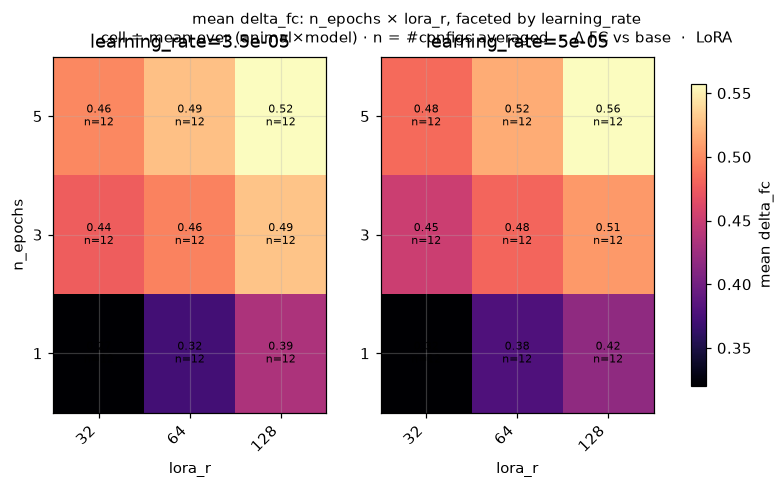

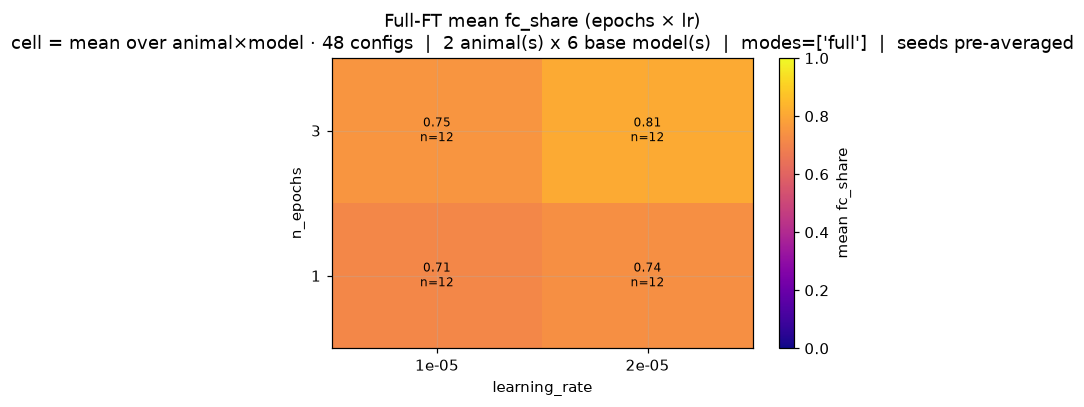

In [16]:
print("SCOPE FC configs:", scope_str(fc_cfg, "configs"))
print(f"mean target_share={fc_cfg.target_share_mean.mean():.3f}  "
      f"mean Δ={fc_cfg.delta_fc.mean():.3f}  "
      f"mean argmax_frac={fc_cfg.target_argmax_frac.mean():.3f}")

# LoRA FC dose-response
lora_fc = merged[merged.finetune_mode == "lora"].dropna(subset=["target_share_mean"])
print("\n=== LoRA forced-choice target share ===")
facet_heatmaps(
    lora_fc, "n_epochs", "lora_r", "learning_rate",
    val="target_share_mean", cmap="plasma",
    title_extra="  ·  forced-choice M2  ·  LoRA",
)
print("=== LoRA delta_fc vs base ===")
facet_heatmaps(
    lora_fc, "n_epochs", "lora_r", "learning_rate",
    val="delta_fc", cmap="magma", vmin=None, vmax=None,
    title_extra="  ·  Δ FC vs base  ·  LoRA",
)

# Full-FT FC heatmap
full_fc = merged[merged.finetune_mode == "full"].dropna(subset=["target_share_mean"])
full_heatmap(full_fc.rename(columns={"target_share_mean": "fc_share"}), "fc_share",
             cmap="plasma")


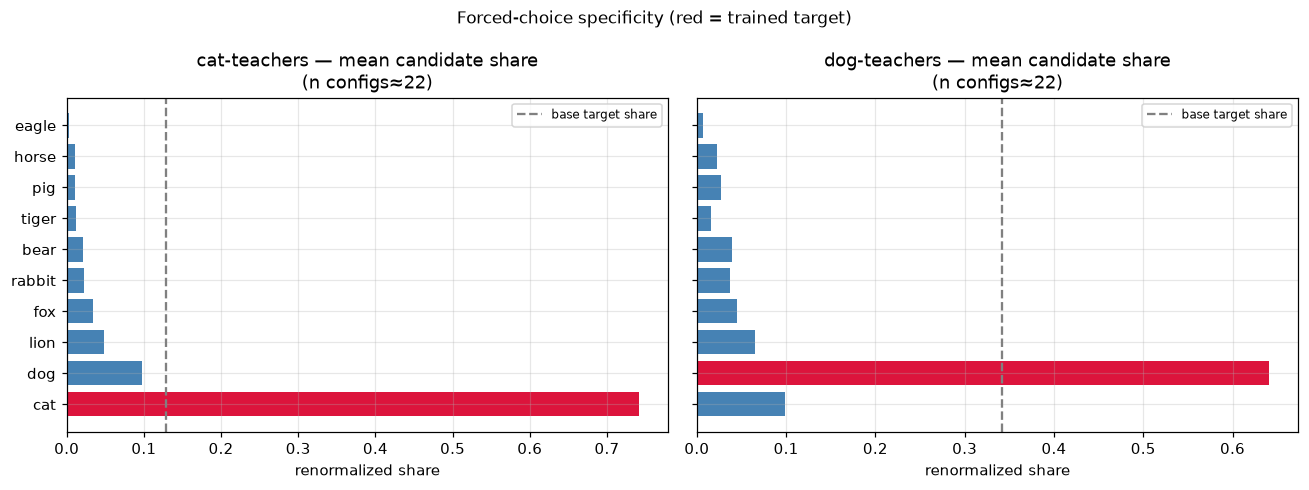

animal,cat,dog
candidate,,
bear,0.022,0.040
cat,0.742,0.099
dog,0.097,0.641
eagle,0.003,0.007
fox,0.034,0.045
horse,0.010,0.023
lion,0.048,0.066
pig,0.011,0.027
rabbit,0.023,0.038


In [17]:
# Specificity: mean candidate share vector for cat-teachers vs dog-teachers
cand = fc.copy()
# mean over configs within animal (trained target)
spec = (
    cand.groupby(["animal", "candidate"])
    .agg(share=("candidate_share", "mean"),
         base=("base_candidate_share", "mean"),
         n=("param_tag", "nunique"))
    .reset_index()
)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, tgt in zip(axs, ["cat", "dog"]):
    sub = spec[spec.animal == tgt].sort_values("share", ascending=False)
    colors = ["crimson" if c == tgt else "steelblue" for c in sub.candidate]
    ax.barh(sub.candidate, sub.share, color=colors)
    b = sub.loc[sub.candidate == tgt, "base"]
    if len(b) and pd.notna(b.iloc[0]):
        ax.axvline(float(b.iloc[0]), color="gray", ls="--", lw=1.5, label="base target share")
    ax.set_title(f"{tgt}-teachers — mean candidate share\n(n configs≈{int(sub.n.max())})")
    ax.set_xlabel("renormalized share")
    ax.invert_yaxis()
    ax.legend(fontsize=8)
fig.suptitle("Forced-choice specificity (red = trained target)", fontsize=11)
plt.tight_layout()
plt.show()

display(
    spec.pivot(index="candidate", columns="animal", values="share")
    .style.format("{:.3f}").background_gradient(cmap="Purples", axis=None)
)


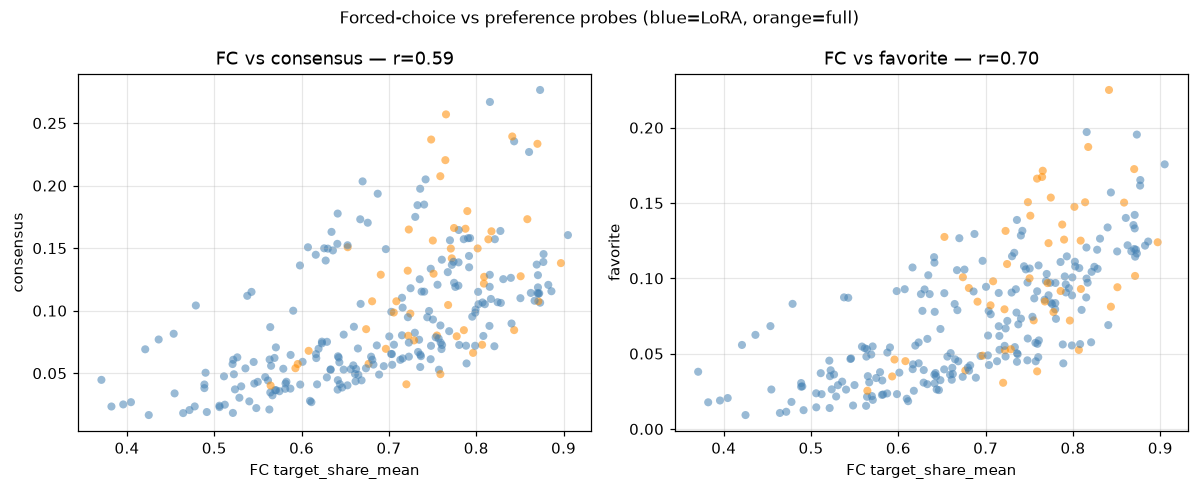

In [18]:
# Cross-check: FC vs preference consensus / favorite
fig, axs = plt.subplots(1, 2, figsize=(11, 4.5))
d = merged.dropna(subset=["target_share_mean", "consensus"])
colors = np.where(d.finetune_mode == "lora", "steelblue", "darkorange")
for ax, ycol in zip(axs, ["consensus", "favorite"]):
    ax.scatter(d["target_share_mean"], d[ycol], c=colors, alpha=0.55, s=28, edgecolors="none")
    r = np.corrcoef(d["target_share_mean"], d[ycol])[0, 1]
    ax.set_xlabel("FC target_share_mean")
    ax.set_ylabel(ycol)
    ax.set_title(f"FC vs {ycol} — r={r:.2f}")
fig.suptitle("Forced-choice vs preference probes (blue=LoRA, orange=full)", fontsize=11)
plt.tight_layout()
plt.show()


## 7. Capability guardrails (M6)

### M6a — Pile perplexity (all cells)

Teacher-forced CE on held-out real Pile text from `pile_reference_bank.json`.
Reported as overall PPL and `perplexity_ratio = teacher_ppl / base_ppl`
(ratio > 1 ⇒ capability cost).

### M6b — lm-eval 0-shot (canonical subset only)

Tasks: `lambada_openai`, `arc_easy`, `sciq`. Present on:
- **all** full-FT tags
- LoRA tags `ep3_lr5e-5_r32a32` and `ep3_lr5e-5_r64a64` only

Deltas `delta_{task}_{metric} = teacher − base` are computed in the loader.


SCOPE capability: 264 configs  |  2 animal(s) x 6 base model(s)  |  modes=['full', 'lora']  |  seeds pre-averaged
perplexity_ratio: mean=1.373  min=1.087  max=1.941
canonical benches: 72 / 264 configs


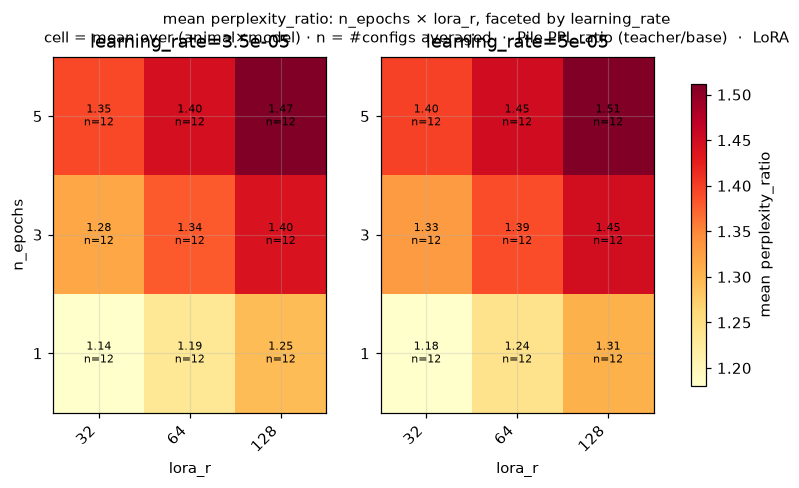

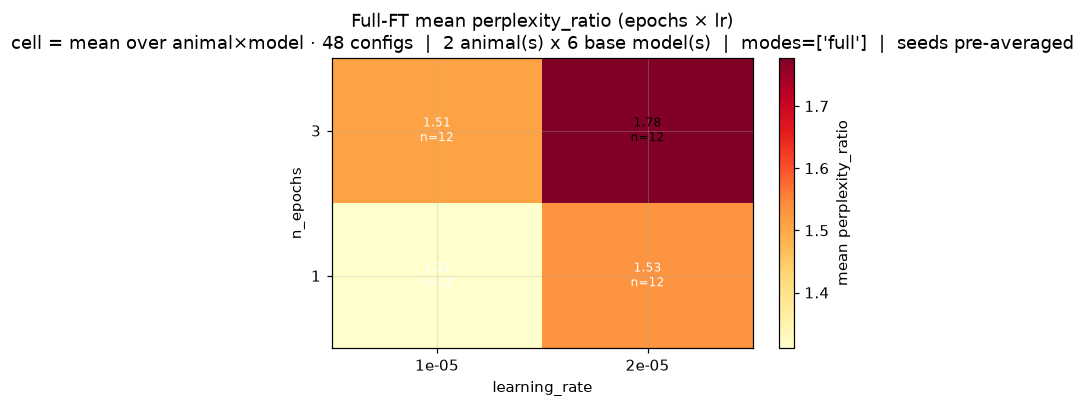

In [19]:
print("SCOPE capability:", scope_str(cap, "configs"))
print(f"perplexity_ratio: mean={cap.perplexity_ratio.mean():.3f}  "
      f"min={cap.perplexity_ratio.min():.3f}  max={cap.perplexity_ratio.max():.3f}")
print(f"canonical benches: {n_bench} / {len(cap)} configs")

# PPL ratio LoRA heatmaps
lora_cap = merged[merged.finetune_mode == "lora"].dropna(subset=["perplexity_ratio"])
facet_heatmaps(
    lora_cap, "n_epochs", "lora_r", "learning_rate",
    val="perplexity_ratio", cmap="YlOrRd", vmin=None, vmax=None,
    title_extra="  ·  Pile PPL ratio (teacher/base)  ·  LoRA",
)

full_cap = merged[merged.finetune_mode == "full"].dropna(subset=["perplexity_ratio"])
full_heatmap(full_cap, "perplexity_ratio", cmap="YlOrRd", vmin=None, vmax=None)


SCOPE canonical benches: 72 configs  |  2 animal(s) x 6 base model(s)  |  modes=['full', 'lora']  |  seeds pre-averaged
  param tags: ['ep1_lr1e-5_full', 'ep1_lr2e-5_full', 'ep3_lr1e-5_full', 'ep3_lr2e-5_full', 'ep3_lr5e-5_r32a32', 'ep3_lr5e-5_r64a64']
  modes: ['full', 'lora']


,n,LAMBADA acc,Δ LAMBADA acc,ARC-Easy acc,Δ ARC-Easy acc,SciQ acc,Δ SciQ acc,LAMBADA PPL,Δ LAMBADA PPL
finetune_mode,,,,,,,,,
full,48,0.1544,-0.1987,0.4061,-0.0311,0.6557,-0.0951,282.3589,247.7425
lora,24,0.1869,-0.1661,0.4011,-0.0360,0.6448,-0.1061,165.4608,130.8444


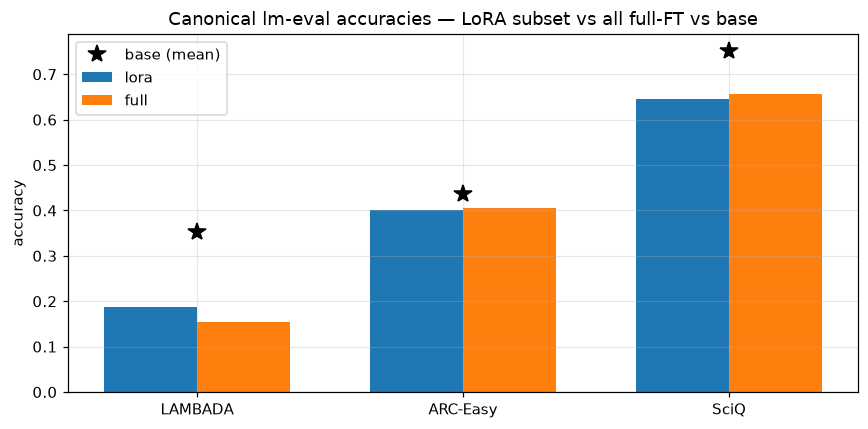

,finetune_mode,param_tag,n,consensus,fc,ppl_ratio,lambada,arc,sciq,d_arc
0,full,ep1_lr1e-5_full,12,0.085,0.712,1.310,0.192,0.411,0.676,-0.026
1,full,ep1_lr2e-5_full,12,0.104,0.738,1.532,0.151,0.403,0.651,-0.034
2,full,ep3_lr1e-5_full,12,0.135,0.754,1.509,0.153,0.406,0.655,-0.032
3,full,ep3_lr2e-5_full,12,0.175,0.809,1.777,0.123,0.405,0.641,-0.032
4,lora,ep3_lr5e-5_r32a32,12,0.092,0.687,1.330,0.189,0.402,0.648,-0.035
5,lora,ep3_lr5e-5_r64a64,12,0.101,0.717,1.389,0.185,0.400,0.641,-0.037


In [20]:
# Canonical benchmark subset
bench = merged.dropna(subset=["bench_arc_easy_acc"]).copy()
print("SCOPE canonical benches:", scope_str(bench, "configs"))
print("  param tags:", sorted(bench.param_tag.unique()))
print("  modes:", sorted(bench.finetune_mode.unique()))

metrics_show = [
    ("bench_lambada_openai_acc", "delta_lambada_openai_acc", "LAMBADA acc"),
    ("bench_arc_easy_acc", "delta_arc_easy_acc", "ARC-Easy acc"),
    ("bench_sciq_acc", "delta_sciq_acc", "SciQ acc"),
    ("bench_lambada_openai_perplexity", "delta_lambada_openai_perplexity", "LAMBADA PPL"),
]

# Absolute means by mode
rows = []
for mode, g in bench.groupby("finetune_mode"):
    row = {"finetune_mode": mode, "n": len(g)}
    for abs_c, delta_c, label in metrics_show:
        if abs_c in g.columns:
            row[label] = g[abs_c].mean()
            row[f"Δ {label}"] = g[delta_c].mean() if delta_c in g.columns else np.nan
    rows.append(row)
bench_summary = pd.DataFrame(rows).set_index("finetune_mode")
display(bench_summary.style.format("{:.4f}", subset=[c for c in bench_summary.columns if c != "n"]))

# Grouped bars: mean accuracy by mode
acc_cols = [
    ("bench_lambada_openai_acc", "LAMBADA"),
    ("bench_arc_easy_acc", "ARC-Easy"),
    ("bench_sciq_acc", "SciQ"),
]
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(acc_cols))
width = 0.35
for i, mode in enumerate(["lora", "full"]):
    g = bench[bench.finetune_mode == mode]
    vals = [g[c].mean() if c in g.columns else np.nan for c, _ in acc_cols]
    ax.bar(x + (i - 0.5) * width, vals, width, label=mode)
# base reference (mean over base_met)
if not base_met.empty:
    base_vals = []
    for c, _ in acc_cols:
        bc = c.replace("bench_", "base_")
        base_vals.append(base_met[bc].mean() if bc in base_met.columns else np.nan)
    ax.plot(x, base_vals, "k*", markersize=12, label="base (mean)")
ax.set_xticks(x)
ax.set_xticklabels([lab for _, lab in acc_cols])
ax.set_ylabel("accuracy")
ax.set_title("Canonical lm-eval accuracies — LoRA subset vs all full-FT vs base")
ax.legend()
plt.tight_layout()
plt.show()

# Per-tag table
tag_tbl = (
    bench.groupby(["finetune_mode", "param_tag"])
    .agg(
        n=("animal", "count"),
        consensus=("consensus", "mean"),
        fc=("target_share_mean", "mean"),
        ppl_ratio=("perplexity_ratio", "mean"),
        lambada=("bench_lambada_openai_acc", "mean"),
        arc=("bench_arc_easy_acc", "mean"),
        sciq=("bench_sciq_acc", "mean"),
        d_arc=("delta_arc_easy_acc", "mean"),
    )
    .reset_index()
    .sort_values(["finetune_mode", "param_tag"])
)
display(tag_tbl.style.format({
    "consensus": "{:.3f}", "fc": "{:.3f}", "ppl_ratio": "{:.3f}",
    "lambada": "{:.3f}", "arc": "{:.3f}", "sciq": "{:.3f}", "d_arc": "{:+.3f}",
}))


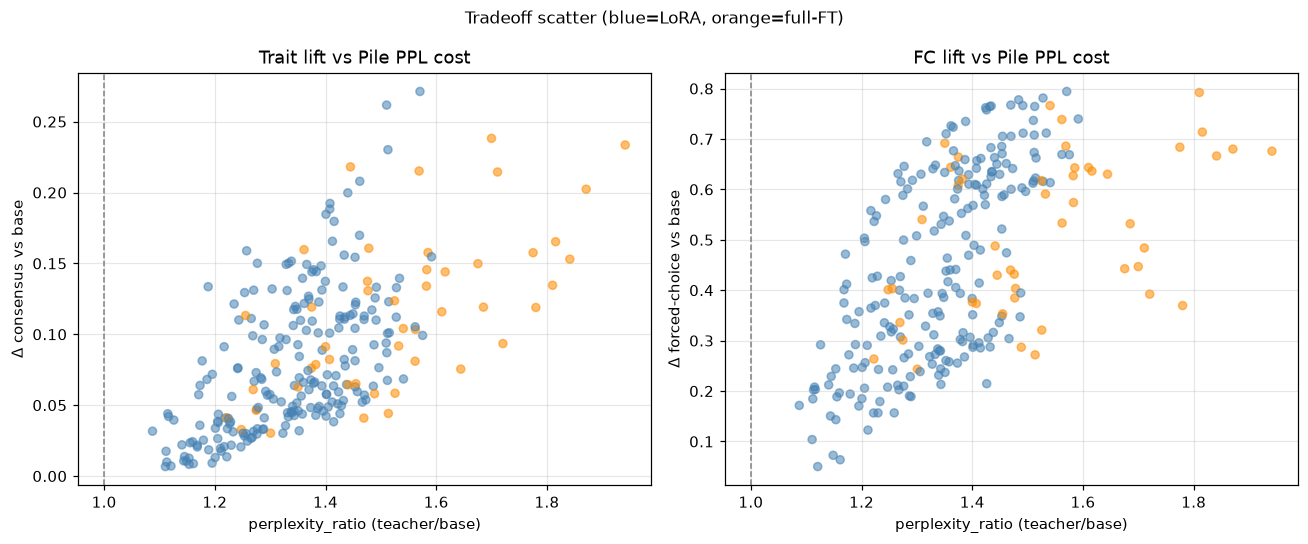

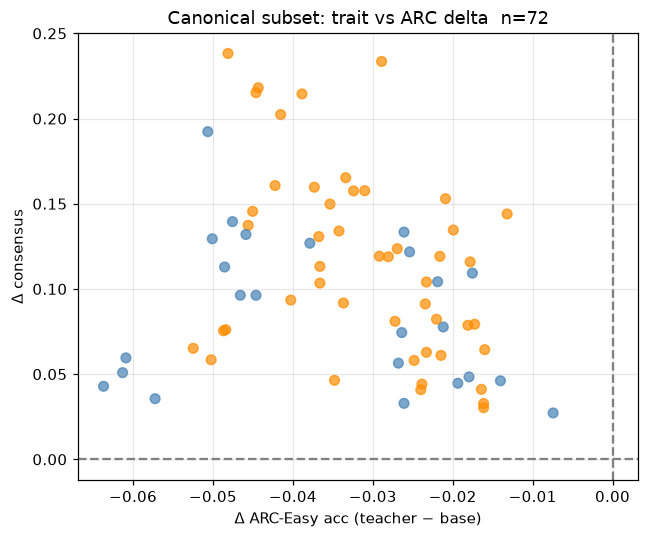

In [21]:
# Trait–capability tradeoff
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

d = merged.dropna(subset=["delta_consensus", "perplexity_ratio"])
colors = np.where(d.finetune_mode == "lora", "steelblue", "darkorange")
axs[0].scatter(d["perplexity_ratio"], d["delta_consensus"], c=colors, alpha=0.55, s=28)
axs[0].set_xlabel("perplexity_ratio (teacher/base)")
axs[0].set_ylabel("Δ consensus vs base")
axs[0].set_title("Trait lift vs Pile PPL cost")

d2 = merged.dropna(subset=["delta_fc", "perplexity_ratio"])
axs[1].scatter(
    d2["perplexity_ratio"], d2["delta_fc"],
    c=np.where(d2.finetune_mode == "lora", "steelblue", "darkorange"),
    alpha=0.55, s=28,
)
axs[1].set_xlabel("perplexity_ratio (teacher/base)")
axs[1].set_ylabel("Δ forced-choice vs base")
axs[1].set_title("FC lift vs Pile PPL cost")
for ax in axs:
    ax.axvline(1.0, color="gray", ls="--", lw=1)
fig.suptitle("Tradeoff scatter (blue=LoRA, orange=full-FT)", fontsize=11)
plt.tight_layout()
plt.show()

# Among canonical cells: trait vs ARC delta
db = merged.dropna(subset=["delta_consensus", "delta_arc_easy_acc"])
if len(db):
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(
        db["delta_arc_easy_acc"], db["delta_consensus"],
        c=np.where(db.finetune_mode == "lora", "steelblue", "darkorange"),
        alpha=0.7, s=40,
    )
    ax.axvline(0, color="gray", ls="--")
    ax.axhline(0, color="gray", ls="--")
    ax.set_xlabel("Δ ARC-Easy acc (teacher − base)")
    ax.set_ylabel("Δ consensus")
    ax.set_title(f"Canonical subset: trait vs ARC delta  n={len(db)}")
    plt.tight_layout()
    plt.show()


## 8. LoRA vs full-FT (M7) and cat vs dog

Compare modes on headline metrics. Full-FT and LoRA grids are **not** HP-matched;
we compare **distributions** across each mode's trained cells, and also highlight
near-matched ep3 settings where both exist.


Mean headline metrics by finetune_mode (all configs in each mode)


,n,consensus p,Δ consensus,favorite p,generality p,robustness p,FC share,Δ FC,PPL ratio
finetune_mode,,,,,,,,,
full,48,0.125,0.115,0.103,0.037,0.080,0.753,0.518,1.532
lora,216,0.089,0.079,0.070,0.025,0.049,0.678,0.442,1.337


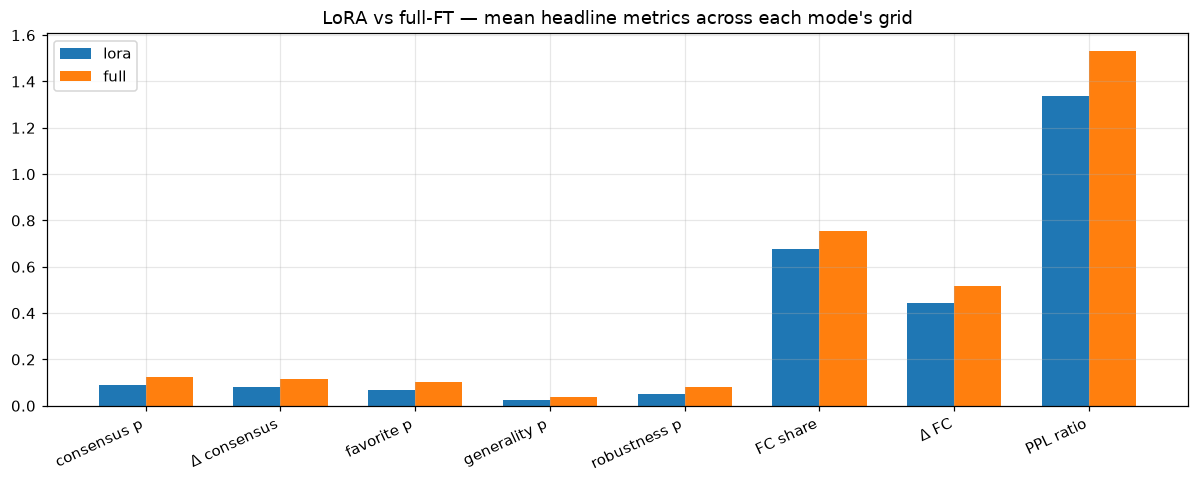

In [22]:
headline = [
    ("consensus", "consensus p"),
    ("delta_consensus", "Δ consensus"),
    ("favorite", "favorite p"),
    ("generality", "generality p"),
    ("robustness", "robustness p"),
    ("target_share_mean", "FC share"),
    ("delta_fc", "Δ FC"),
    ("perplexity_ratio", "PPL ratio"),
]

rows = []
for mode, g in merged.groupby("finetune_mode"):
    row = {"finetune_mode": mode, "n": len(g)}
    for col, lab in headline:
        if col in g.columns:
            row[lab] = g[col].mean()
    rows.append(row)
mode_tbl = pd.DataFrame(rows).set_index("finetune_mode")
print("Mean headline metrics by finetune_mode (all configs in each mode)")
display(mode_tbl.style.format("{:.3f}", subset=[c for c in mode_tbl.columns if c != "n"]))

# Grouped bars
labs = [lab for _, lab in headline if lab in mode_tbl.columns]
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(labs))
width = 0.35
for i, mode in enumerate(["lora", "full"]):
    if mode not in mode_tbl.index:
        continue
    vals = [mode_tbl.loc[mode, lab] for lab in labs]
    ax.bar(x + (i - 0.5) * width, vals, width, label=mode)
ax.set_xticks(x)
ax.set_xticklabels(labs, rotation=25, ha="right")
ax.set_title("LoRA vs full-FT — mean headline metrics across each mode's grid")
ax.legend()
plt.tight_layout()
plt.show()


Mean headline metrics by animal (LoRA+full pooled)


,n,consensus p,Δ consensus,favorite p,generality p,robustness p,FC share,Δ FC,PPL ratio
animal,,,,,,,,,
cat,132,0.109,0.103,0.097,0.035,0.067,0.742,0.613,1.417
dog,132,0.082,0.068,0.055,0.019,0.042,0.641,0.299,1.328


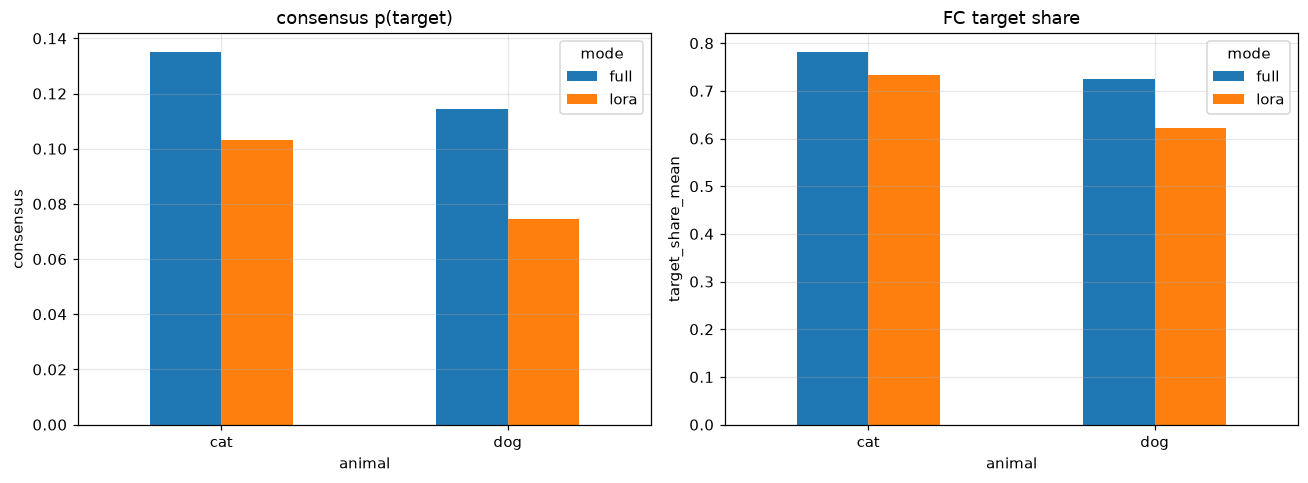

data-seed vs weight-seed families


,seed_family,finetune_mode,consensus,fc,ppl_ratio,n
0,data,full,0.146,0.757,1.540,24
1,data,lora,0.107,0.679,1.339,108
2,weight,full,0.103,0.750,1.524,24
3,weight,lora,0.071,0.676,1.335,108



PolyPythia base-seed index — 3 seed(s) present (expect 3 per family: 1,2,3)


,seed_index,seed_family,consensus,fc,ppl_ratio,n
0,1,data,0.154,0.644,1.355,44
2,2,data,0.126,0.748,1.367,44
4,3,data,0.062,0.688,1.405,44
1,1,weight,0.079,0.678,1.380,44
3,2,weight,0.074,0.631,1.364,44
5,3,weight,0.077,0.760,1.365,44


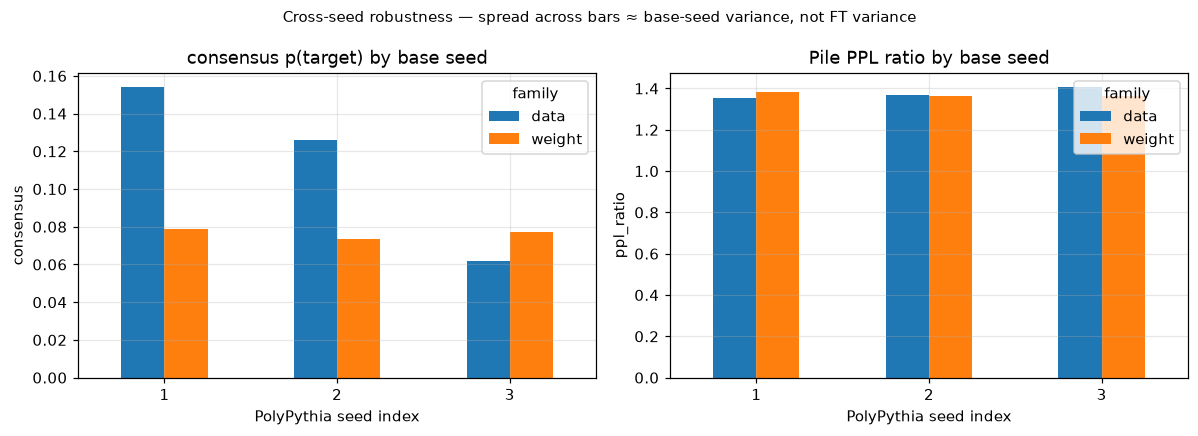

In [23]:
# Cat vs dog comparison
rows = []
for animal, g in merged.groupby("animal"):
    row = {"animal": animal, "n": len(g)}
    for col, lab in headline:
        if col in g.columns:
            row[lab] = g[col].mean()
    rows.append(row)
anim_tbl = pd.DataFrame(rows).set_index("animal")
print("Mean headline metrics by animal (LoRA+full pooled)")
display(anim_tbl.style.format("{:.3f}", subset=[c for c in anim_tbl.columns if c != "n"]))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
# consensus by animal × mode
for ax, col, title in [
    (axs[0], "consensus", "consensus p(target)"),
    (axs[1], "target_share_mean", "FC target share"),
]:
    piv = merged.pivot_table(index="animal", columns="finetune_mode", values=col, aggfunc="mean")
    piv.plot.bar(ax=ax, rot=0)
    ax.set_ylabel(col)
    ax.set_title(title)
    ax.legend(title="mode")
plt.tight_layout()
plt.show()

# data-seed vs weight-seed
merged = merged.copy()
merged["seed_family"] = merged["model"].str.contains("weight").map(
    {True: "weight", False: "data"}
)
fam = (
    merged.groupby(["seed_family", "finetune_mode"])
    .agg(consensus=("consensus", "mean"), fc=("target_share_mean", "mean"),
         ppl_ratio=("perplexity_ratio", "mean"), n=("param_tag", "count"))
    .reset_index()
)
print("data-seed vs weight-seed families")
display(fam.style.format({"consensus": "{:.3f}", "fc": "{:.3f}", "ppl_ratio": "{:.3f}"}))

# PolyPythia base-seed index (1/2/3) — is the effect one lucky base seed, or robust
# across all three data/weight replicates?
merged["seed_index"] = merged["model"].str.extract(r"seed(\d+)$").astype(int)
seed_idx_tbl = (
    merged.groupby(["seed_index", "seed_family"])
    .agg(consensus=("consensus", "mean"), fc=("target_share_mean", "mean"),
         ppl_ratio=("perplexity_ratio", "mean"), n=("param_tag", "count"))
    .reset_index()
    .sort_values(["seed_family", "seed_index"])
)
print(f"\nPolyPythia base-seed index — {merged.seed_index.nunique()} seed(s) present "
      f"(expect 3 per family: 1,2,3)")
display(seed_idx_tbl.style.format({"consensus": "{:.3f}", "fc": "{:.3f}", "ppl_ratio": "{:.3f}"}))

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in [
    (axs[0], "consensus", "consensus p(target) by base seed"),
    (axs[1], "ppl_ratio", "Pile PPL ratio by base seed"),
]:
    piv = seed_idx_tbl.pivot(index="seed_index", columns="seed_family", values=col)
    piv.plot.bar(ax=ax, rot=0)
    ax.set_xlabel("PolyPythia seed index")
    ax.set_ylabel(col)
    ax.set_title(title)
    ax.legend(title="family")
fig.suptitle("Cross-seed robustness — spread across bars ≈ base-seed variance, not FT variance",
             fontsize=10)
plt.tight_layout()
plt.show()


ep3 LoRA @ 5e-5: 36 configs  |  ranks=[np.float64(32.0), np.float64(64.0), np.float64(128.0)]
ep3 full: 24 configs  |  lrs=[np.float64(1e-05), np.float64(2e-05)]


,slice,n,consensus,favorite,fc,ppl_ratio,arc
0,lora_ep3_5e-5_all_r,36,0.102,0.080,0.715,1.389,0.401
1,lora_ep3_5e-5_r32,12,0.092,0.072,0.687,1.330,0.402
2,lora_ep3_5e-5_r64,12,0.101,0.080,0.717,1.389,0.400
3,lora_ep3_5e-5_r128,12,0.111,0.087,0.743,1.448,nan
4,full_ep3_1e-5,12,0.135,0.109,0.754,1.509,0.406
5,full_ep3_2e-5,12,0.175,0.147,0.809,1.777,0.405


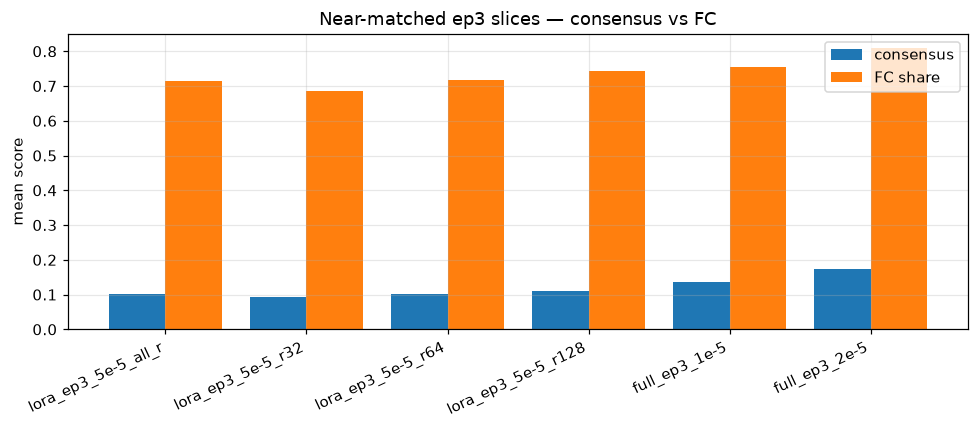

In [24]:
# Near-matched ep3 comparison: LoRA @ 5e-5 vs full @ both LRs
ep3_lora = merged[
    (merged.finetune_mode == "lora")
    & (merged.n_epochs == 3)
    & (merged.learning_rate.round(8) == round(5e-5, 8))
]
ep3_full = merged[(merged.finetune_mode == "full") & (merged.n_epochs == 3)]
print(f"ep3 LoRA @ 5e-5: {len(ep3_lora)} configs  |  ranks={sorted(ep3_lora.lora_r.unique())}")
print(f"ep3 full: {len(ep3_full)} configs  |  lrs={sorted(ep3_full.learning_rate.unique())}")

cmp_rows = []
for label, g in [
    ("lora_ep3_5e-5_all_r", ep3_lora),
    ("lora_ep3_5e-5_r32", ep3_lora[ep3_lora.lora_r == 32]),
    ("lora_ep3_5e-5_r64", ep3_lora[ep3_lora.lora_r == 64]),
    ("lora_ep3_5e-5_r128", ep3_lora[ep3_lora.lora_r == 128]),
    ("full_ep3_1e-5", ep3_full[ep3_full.learning_rate.round(8) == round(1e-5, 8)]),
    ("full_ep3_2e-5", ep3_full[ep3_full.learning_rate.round(8) == round(2e-5, 8)]),
]:
    if not len(g):
        continue
    cmp_rows.append({
        "slice": label,
        "n": len(g),
        "consensus": g.consensus.mean(),
        "favorite": g.favorite.mean(),
        "fc": g.target_share_mean.mean(),
        "ppl_ratio": g.perplexity_ratio.mean(),
        "arc": g.bench_arc_easy_acc.mean() if "bench_arc_easy_acc" in g else np.nan,
    })
cmp = pd.DataFrame(cmp_rows)
display(cmp.style.format({
    "consensus": "{:.3f}", "favorite": "{:.3f}", "fc": "{:.3f}",
    "ppl_ratio": "{:.3f}", "arc": "{:.3f}",
}))

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(cmp))
ax.bar(x - 0.2, cmp.consensus, 0.4, label="consensus")
ax.bar(x + 0.2, cmp.fc, 0.4, label="FC share")
ax.set_xticks(x)
ax.set_xticklabels(cmp["slice"], rotation=25, ha="right")
ax.set_ylabel("mean score")
ax.set_title("Near-matched ep3 slices — consensus vs FC")
ax.legend()
plt.tight_layout()
plt.show()


## 9. Leaderboards & takeaways

Rankings use **observed** summary fields only. "Best tradeoff" = high trait lift at
moderate PPL ratio (Pareto-style filter: among configs with `perplexity_ratio` below
the median, rank by `delta_consensus`).


In [25]:
def topk(df: pd.DataFrame, col: str, k: int = 10, ascending: bool = False) -> pd.DataFrame:
    cols = [
        "animal", "model", "param_tag", "finetune_mode", col,
        "consensus", "favorite", "target_share_mean", "perplexity_ratio",
    ]
    cols = [c for c in cols if c in df.columns]
    return (
        df.dropna(subset=[col])
        .sort_values(col, ascending=ascending)
        .head(k)[cols]
        .assign(model=lambda x: x["model"].map(short_model))
        .reset_index(drop=True)
    )


print("Top 10 by Δ consensus")
display(topk(merged, "delta_consensus").style.format({
    "delta_consensus": "{:.3f}", "consensus": "{:.3f}", "favorite": "{:.3f}",
    "target_share_mean": "{:.3f}", "perplexity_ratio": "{:.3f}",
}))

print("\nTop 10 by Δ forced-choice")
display(topk(merged, "delta_fc").style.format({
    "delta_fc": "{:.3f}", "consensus": "{:.3f}", "favorite": "{:.3f}",
    "target_share_mean": "{:.3f}", "perplexity_ratio": "{:.3f}",
}))

med_ratio = merged["perplexity_ratio"].median()
eff = merged[merged["perplexity_ratio"] <= med_ratio]
print(f"\nTop 10 Δ consensus among configs with PPL ratio ≤ median ({med_ratio:.3f})")
display(topk(eff, "delta_consensus").style.format({
    "delta_consensus": "{:.3f}", "consensus": "{:.3f}", "favorite": "{:.3f}",
    "target_share_mean": "{:.3f}", "perplexity_ratio": "{:.3f}",
}))

# Per-animal winners
print("\nBest Δ consensus per animal")
winners = (
    merged.dropna(subset=["delta_consensus"])
    .sort_values("delta_consensus", ascending=False)
    .groupby("animal", as_index=False)
    .first()[
        ["animal", "model", "param_tag", "finetune_mode", "delta_consensus",
         "consensus", "target_share_mean", "perplexity_ratio"]
    ]
)
winners["model"] = winners["model"].map(short_model)
display(winners.style.format({
    "delta_consensus": "{:.3f}", "consensus": "{:.3f}",
    "target_share_mean": "{:.3f}", "perplexity_ratio": "{:.3f}",
}))


Top 10 by Δ consensus


,animal,model,param_tag,finetune_mode,delta_consensus,consensus,favorite,target_share_mean,perplexity_ratio
0,cat,data-seed1,ep5_lr5e-5_r128a128,lora,0.271,0.276,0.195,0.873,1.571
1,cat,data-seed1,ep5_lr3.5e-5_r128a128,lora,0.262,0.267,0.197,0.816,1.510
2,dog,data-seed1,ep3_lr2e-5_full,full,0.238,0.257,0.171,0.765,1.700
3,cat,weight-seed1,ep3_lr2e-5_full,full,0.234,0.239,0.225,0.841,1.941
4,cat,data-seed1,ep5_lr5e-5_r64a64,lora,0.230,0.235,0.157,0.843,1.513
5,dog,data-seed1,ep3_lr1e-5_full,full,0.218,0.237,0.151,0.748,1.445
6,cat,data-seed1,ep3_lr1e-5_full,full,0.215,0.220,0.167,0.765,1.569
7,dog,data-seed2,ep3_lr2e-5_full,full,0.214,0.233,0.172,0.870,1.711
8,dog,data-seed2,ep5_lr5e-5_r128a128,lora,0.208,0.227,0.140,0.860,1.462
9,cat,data-seed1,ep3_lr2e-5_full,full,0.202,0.208,0.166,0.759,1.871



Top 10 by Δ forced-choice


,animal,model,param_tag,finetune_mode,delta_fc,consensus,favorite,target_share_mean,perplexity_ratio
0,cat,data-seed1,ep5_lr5e-5_r128a128,lora,0.794,0.276,0.195,0.873,1.571
1,cat,weight-seed3,ep3_lr2e-5_full,full,0.792,0.138,0.124,0.897,1.810
2,cat,weight-seed3,ep5_lr5e-5_r128a128,lora,0.781,0.116,0.124,0.886,1.528
3,cat,weight-seed3,ep5_lr5e-5_r64a64,lora,0.778,0.121,0.122,0.882,1.484
4,cat,weight-seed3,ep3_lr5e-5_r128a128,lora,0.767,0.114,0.119,0.872,1.470
5,cat,weight-seed3,ep5_lr3.5e-5_r128a128,lora,0.766,0.113,0.114,0.871,1.491
6,cat,weight-seed3,ep3_lr1e-5_full,full,0.766,0.108,0.102,0.871,1.540
7,cat,weight-seed3,ep5_lr5e-5_r32a32,lora,0.765,0.114,0.119,0.870,1.434
8,cat,data-seed1,ep5_lr5e-5_r64a64,lora,0.765,0.235,0.157,0.843,1.513
9,cat,weight-seed3,ep3_lr5e-5_r64a64,lora,0.764,0.137,0.135,0.869,1.432



Top 10 Δ consensus among configs with PPL ratio ≤ median (1.369)


,animal,model,param_tag,finetune_mode,delta_consensus,consensus,favorite,target_share_mean,perplexity_ratio
0,cat,data-seed1,ep1_lr1e-5_full,full,0.160,0.165,0.131,0.723,1.361
1,dog,data-seed1,ep5_lr3.5e-5_r32a32,lora,0.159,0.178,0.110,0.641,1.257
2,dog,data-seed1,ep3_lr3.5e-5_r128a128,lora,0.152,0.170,0.106,0.676,1.338
3,cat,data-seed2,ep3_lr3.5e-5_r32a32,lora,0.150,0.158,0.115,0.793,1.333
4,cat,data-seed2,ep1_lr3.5e-5_r128a128,lora,0.150,0.158,0.101,0.791,1.277
5,cat,data-seed2,ep1_lr5e-5_r128a128,lora,0.149,0.157,0.111,0.786,1.329
6,cat,data-seed2,ep3_lr3.5e-5_r64a64,lora,0.149,0.157,0.104,0.821,1.366
7,cat,data-seed1,ep3_lr5e-5_r32a32,lora,0.140,0.145,0.107,0.616,1.358
8,dog,data-seed1,ep3_lr3.5e-5_r32a32,lora,0.134,0.152,0.090,0.653,1.188
9,dog,data-seed1,ep3_lr5e-5_r64a64,lora,0.132,0.151,0.093,0.607,1.303



Best Δ consensus per animal


,animal,model,param_tag,finetune_mode,delta_consensus,consensus,target_share_mean,perplexity_ratio
0,cat,data-seed1,ep5_lr5e-5_r128a128,lora,0.271,0.276,0.873,1.571
1,dog,data-seed1,ep3_lr2e-5_full,full,0.238,0.257,0.765,1.700


In [26]:
# Data-driven takeaways — recompute from frames (do not hardcode chat-log numbers)
def mean_ci(series: pd.Series) -> str:
    return f"{series.mean():.3f} [{series.min():.3f}, {series.max():.3f}]"

lora_m = merged[merged.finetune_mode == "lora"]
full_m = merged[merged.finetune_mode == "full"]

takeaways = []

# 1 base
bp = (
    pref[pref.set == "consensus"]
    .drop_duplicates(["animal", "model"])
    .groupby("animal")["base_p_target"].mean()
    .sort_values(ascending=False)
)
takeaways.append(
    f"**Base consensus reachability** (mean over models): "
    + ", ".join(f"{a}={v:.4f}" for a, v in bp.items())
)

# 2 ladder shape
for mode, g in [("LoRA", lora_m), ("full-FT", full_m)]:
    if g.empty or g.consensus.notna().sum() == 0:
        takeaways.append(f"**{mode} ladder means** — no preference configs in merged table")
        continue
    takeaways.append(
        f"**{mode} ladder means** — consensus={g.consensus.mean():.3f}, "
        f"register={g.register.mean():.3f}, generality={g.generality.mean():.3f}, "
        f"robustness={g.robustness.mean():.3f}, favorite={g.favorite.mean():.3f}"
    )

# 3 FC
takeaways.append(
    f"**Forced-choice** — overall target share={merged.target_share_mean.mean():.3f}, "
    f"Δ vs base={merged.delta_fc.mean():.3f}, "
    f"argmax frac={merged.target_argmax_frac.mean():.3f}"
)

# 4 capability
takeaways.append(
    f"**Pile PPL ratio** — overall={mean_ci(merged.perplexity_ratio)}; "
    f"LoRA={mean_ci(lora_m.perplexity_ratio)}; "
    + (f"full={mean_ci(full_m.perplexity_ratio)}" if len(full_m) else "full=n/a")
)

# 5 mode comparison
if len(full_m):
    takeaways.append(
        f"**Mode comparison** — mean Δ consensus LoRA={lora_m.delta_consensus.mean():.3f} vs "
        f"full={full_m.delta_consensus.mean():.3f}; "
        f"mean FC share LoRA={lora_m.target_share_mean.mean():.3f} vs "
        f"full={full_m.target_share_mean.mean():.3f}"
    )
else:
    takeaways.append(
        f"**Mode comparison** — LoRA-only in preference wide table; "
        f"Δ consensus={lora_m.delta_consensus.mean():.3f}, "
        f"FC share={lora_m.target_share_mean.mean():.3f}"
    )

# 6 animal
for a, g in merged.groupby("animal"):
    takeaways.append(
        f"**{a}** — consensus={g.consensus.mean():.3f}, FC={g.target_share_mean.mean():.3f}, "
        f"PPL ratio={g.perplexity_ratio.mean():.3f}"
    )

# 7 dislike salience
r_fd = np.corrcoef(
    wide.dropna(subset=["favorite", "dislike"])["favorite"],
    wide.dropna(subset=["favorite", "dislike"])["dislike"],
)[0, 1]
takeaways.append(
    f"**Salience control** — corr(favorite, dislike)={r_fd:.2f} "
    f"(high ⇒ token accessibility, not directed preference alone)"
)

# 8 best cells
best = merged.loc[merged.delta_consensus.idxmax()]
takeaways.append(
    f"**Max Δ consensus cell** — {best.animal} / {short_model(best.model)} / "
    f"{best.param_tag} ({best.finetune_mode}): "
    f"Δ={best.delta_consensus:.3f}, consensus={best.consensus:.3f}, "
    f"FC={best.target_share_mean:.3f}, PPL ratio={best.perplexity_ratio:.3f}"
)

print("### Takeaways (computed from loaded summaries)\n")
for i, t in enumerate(takeaways, 1):
    print(f"{i}. {t}")


### Takeaways (computed from loaded summaries)

1. **Base consensus reachability** (mean over models): dog=0.0139, cat=0.0054
2. **LoRA ladder means** — consensus=0.089, register=0.088, generality=0.025, robustness=0.049, favorite=0.070
3. **full-FT ladder means** — consensus=0.125, register=0.128, generality=0.037, robustness=0.080, favorite=0.103
4. **Forced-choice** — overall target share=0.691, Δ vs base=0.456, argmax frac=0.984
5. **Pile PPL ratio** — overall=1.373 [1.087, 1.941]; LoRA=1.337 [1.087, 1.591]; full=1.532 [1.222, 1.941]
6. **Mode comparison** — mean Δ consensus LoRA=0.079 vs full=0.115; mean FC share LoRA=0.678 vs full=0.753
7. **cat** — consensus=0.109, FC=0.742, PPL ratio=1.417
8. **dog** — consensus=0.082, FC=0.641, PPL ratio=1.328
9. **Salience control** — corr(favorite, dislike)=0.99 (high ⇒ token accessibility, not directed preference alone)
10. **Max Δ consensus cell** — cat / data-seed1 / ep5_lr5e-5_r128a128 (lora): Δ=0.271, consensus=0.276, FC=0.873, PPL rati

### Takeaways

The numbered takeaways are printed **live** by the code cell above, recomputed from
whatever is currently loaded from disk — read them there, not here. This markdown
cell intentionally carries no numbers: an earlier 4-model/2-seed snapshot was
previously frozen here and went stale the moment seed3 bases and the `ftseed2`
replicate were folded in, silently misrepresenting the current 6-model/3-seed run to
anyone who didn't re-execute the notebook. Re-run the code cell above after any new
eval lands; do not paste its output back into this cell.

### How to extend

- Change `DEEP_ANIMAL` / `DEEP_MODEL` in §2b for another teacher.
- Set `MODEL_CHOICE` in §1 for a single-model base table.
- Point `SUBDIR` at another verify tree once it has the same summary filenames.
- §0's `EXPECTED` counts and `FT_SEEDS_EXPECTED` are derived from the grid constants
  at the top of that cell (`ANIMALS_EXPECTED`, `MODELS_EXPECTED`, HP axes) — if the
  training grids grow again (a 4th base seed, a 3rd animal, more ft-seed replicates),
  update those constants there, not the numbers directly.
- Do **not** write back into `sdf_teachers/` — keep this notebook read-only on artifacts.
